# 03 — Model experiments

**Mục tiêu:** so sánh cấu hình và các họ model trên train/validation cố định, trước khi làm feature engineering và CV. Đơn vị MAE/RMSE: tỷ VND; MAE validation là metric chính.

**Cách dùng:** chọn đúng kernel có các thư viện ở C01; Restart Kernel → Run All để tái lập toàn bộ. Không cài thư viện trong cell experiment. Import chỉ ở C01. Không mở calibration/test.

**Đánh số mới:** code C01–C25 liên tục. Markdown dùng tiêu đề nội dung, không còn thêm mã M. Hướng dẫn sau này ghi “notebook 03, C13”; không dùng số execution `[n]`. Thí nghiệm mới tiếp theo thêm từ C26; chỉ đổi mã khi chủ động tổ chức lại toàn bộ notebook.

| Nhóm | Cell | Nội dung |
|---|---|---|
| Thiết lập | C01–C03 | Imports, split, feature, preprocessing và hàm dùng chung |
| RF | C04–C06 | Depth/leaf, max_features, kiểm tra seed |
| Chẩn đoán | C07–C09 | Phân tích lỗi, kiểm tra và chuẩn hóa địa phương |
| Preprocessing | C10–C15 | Phân phối missing, mean/median, indicator, KNN, categorical |
| Tuyến tính | C16 | Linear Regression, Ridge, ElasticNet |
| Boosting | C17–C20 | CatBoost 1500/3000, XGBoost, LightGBM |
| Tổng hợp | C21 | Bảng tất cả model và lựa chọn tạm thời |

**Phụ thuộc:** chạy từ trên xuống; thay dữ liệu, feature, preprocessing hoặc tham số upstream thì chạy lại các cell phía sau. Output đã lưu không thay thế biến trong kernel. Việc gom nhóm vẫn giữ phụ thuộc thực tế: preprocessing RF phải có trước những model dùng lại thiết lập đó.

Các kết luận trong Markdown dưới đây là **ghi nhận lịch sử trước khi dọn** để giữ quá trình học; bảng code của lần chạy mới là bằng chứng để đối chiếu. Không diễn giải lại một experiment là tối ưu toàn cục. Bản gốc đầy đủ được lưu riêng; xem bảng mã cũ → mới trong báo cáo cleanup.

**RF Grid Search lượt 1 — C22–C25:** chuẩn bị CV, đo đối chứng, chạy grid và đọc kết quả.

Để chỉ chạy RF Grid Search sau Restart Kernel: chạy C01–C03 rồi C22–C25. Không cần chạy lại các experiment C04–C21.


**Mở lại notebook:** chạy C01 → C02 → C03 → S01 → S02, sau đó chạy R01 → R02 ở cuối notebook để khôi phục bảng CV. Các cell này không train model. Không dùng Run All để khôi phục phiên cũ.

S01 tạo lại fold trên train đã lưu, không chia lại các tập dữ liệu. S02 chỉ khai báo cấu hình và hàm preprocessing; chuẩn hóa địa phương được pipeline/hàm áp dụng khi xử lý dữ liệu. Điền thiếu và encoding vẫn học riêng từ phần train của từng fold khi chạy experiment mới.

Các output experiment cũ được giữ để tham khảo; chúng không có nghĩa model vẫn tồn tại trong RAM. C21 là bảng validation; R02 là bảng CV. C27 chỉ đăng ký kết quả khi chủ động chạy lại RF/Ridge.


In [1]:
# C01 — Imports và phiên bản môi trường
from pathlib import Path
from itertools import product
from time import perf_counter
from copy import deepcopy
from importlib.metadata import version
import hashlib
import json
import re
import unicodedata
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import GridSearchCV, KFold, ParameterGrid, cross_validate
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge, ElasticNet
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import catboost
from catboost import CatBoostRegressor
import xgboost
from xgboost import XGBRegressor
import lightgbm as lgb
from sklearn.model_selection import train_test_split

environment_versions = {
    package: version(package)
    for package in ['numpy', 'pandas', 'scikit-learn', 'catboost', 'xgboost', 'lightgbm']
}
display(pd.Series(environment_versions, name='version').to_frame())


,version
numpy,2.5.3
pandas,3.0.6
scikit-learn,1.9.1
catboost,1.2.10
xgboost,3.4.1
lightgbm,4.7.0


In [2]:
# C02 — Đọc train/validation đã cố định
PROJECT_ROOT = next(
    (
        folder
        for folder in [Path.cwd(), *Path.cwd().parents]
        if (
            folder / "data" / "processed"
            / "splits_v1" / "train.csv"
        ).is_file()
        and (folder / "notebooks").is_dir()
    ),
    None,
)
assert PROJECT_ROOT is not None, "Mở kernel trong project hoặc notebooks."

SPLIT_DIR = PROJECT_ROOT / "data" / "processed" / "splits_v1"
SEED = 42
TARGET = "Price"

train_df = pd.read_csv(SPLIT_DIR / "train.csv")
val_df = pd.read_csv(SPLIT_DIR / "validation.csv")

assert train_df["row_id"].is_unique
assert val_df["row_id"].is_unique
assert set(train_df["row_id"]).isdisjoint(val_df["row_id"])
assert (len(train_df), len(val_df)) == (18136, 4535)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
# Nhận diện chính xác phiên bản split, không đọc calibration/test.
split_fingerprints = {
    name: hashlib.sha256((SPLIT_DIR / f'{name}.csv').read_bytes()).hexdigest()
    for name in ['train', 'validation']
}
display(pd.Series(split_fingerprints, name='sha256').to_frame())


Train: (18136, 14)
Validation: (4535, 14)


,sha256
train,047f4f8d482f98f1fb2ee397cc51fa41e45b76409cc7f1...
validation,f864ac624a35010b627eb5ec8e223f6390f90c76eb2922...


In [3]:
# C03 — Feature, preprocessing, metrics và hàm chạy RF
FEATURES = [
    "Area", "Frontage", "Access Road",
    "House direction", "Balcony direction",
    "Floors", "Bedrooms", "Bathrooms",
    "Legal status", "Furniture state", "City", "District",
]

NUMERIC_FEATURES = [
    "Area", "Frontage", "Access Road",
    "Floors", "Bedrooms", "Bathrooms",
]
CATEGORICAL_FEATURES = [
    "House direction", "Balcony direction",
    "Legal status", "Furniture state", "City", "District",
]

for part in [train_df, val_df]:
    assert set(part.columns) == set(FEATURES + [TARGET, "row_id"])
    assert part[TARGET].notna().all()

X_train = train_df[FEATURES].copy()
y_train = train_df[TARGET].copy()
X_val = val_df[FEATURES].copy()
y_val = val_df[TARGET].copy()

preprocessor = ColumnTransformer([
    (
        "num",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]),
        NUMERIC_FEATURES,
    ),
    (
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]),
        CATEGORICAL_FEATURES,
    ),
])

# Ghi rõ các tham số để tái lập baseline.
BASE_RF_PARAMS = {
    "n_estimators": 100,
    "max_depth": None,
    "min_samples_leaf": 1,
    "min_samples_split": 2,
    "max_features": 1.0,
    "random_state": SEED,
    "n_jobs": -1,
}


def evaluate(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "R2": r2_score(y_true, y_pred),
    }


def run_rf(name, changes):
    params = {**BASE_RF_PARAMS, **changes}
    pipeline = Pipeline([
        # Mỗi model có preprocessing riêng.
        ("preprocessor", clone(preprocessor)),
        ("model", RandomForestRegressor(**params)),
    ])

    start = perf_counter()
    pipeline.fit(X_train, y_train)
    fit_seconds = perf_counter() - start

    train_metrics = evaluate(y_train, pipeline.predict(X_train))
    val_metrics = evaluate(y_val, pipeline.predict(X_val))

    return {
        "experiment": name,
        **params,
        **{f"train_{k}": v for k, v in train_metrics.items()},
        **{f"val_{k}": v for k, v in val_metrics.items()},
        "MAE_gap": val_metrics["MAE"] - train_metrics["MAE"],
        "fit_seconds": fit_seconds,
    }
# Kiểm tra đầu vào chung trước mọi experiment.
assert TARGET not in FEATURES and 'row_id' not in FEATURES
assert X_train.index.equals(y_train.index)
assert X_val.index.equals(y_val.index)
assert np.isfinite(y_train.to_numpy()).all()
assert np.isfinite(y_val.to_numpy()).all()
assert y_train.gt(0).all() and y_val.gt(0).all()
for frame in [X_train, X_val]:
    assert all(pd.api.types.is_numeric_dtype(frame[c]) for c in NUMERIC_FEATURES)
    assert not np.isinf(frame[NUMERIC_FEATURES].to_numpy(dtype=float)).any()
assert X_train[FEATURES].notna().any().all(), 'Có cột train hoàn toàn thiếu.'


def normalize_location_name(value):
    """Chuẩn hóa định dạng địa phương; giữ nguyên missing."""
    if pd.isna(value):
        return value

    text = unicodedata.normalize("NFC", str(value))
    text = re.sub(r"\s+", " ", text).strip()
    text = text.rstrip(".").strip()

    # Không âm thầm chuyển tên chỉ gồm dấu câu thành missing.
    return text


def normalize_location_frame(X):
    # Copy để không sửa X_train/X_val hoặc dữ liệu gốc.
    result = X.copy()

    for column in ["City", "District"]:
        result[column] = result[column].map(
            normalize_location_name
        )

        assert not result[column].eq("").fillna(False).any(), (
            f"{column}: chuẩn hóa tạo tên rỗng; cần kiểm tra."
        )

    return result



In [4]:
# S01 — Pipeline CV và fold cố định
assert "X_train" in globals(), "Chạy C01–C03 trước."

# Dựng từ thiết lập chung; không phụ thuộc model đã fit ở C13.
rf_grid_preprocessor = clone(preprocessor)
rf_grid_preprocessor.set_params(num=Pipeline([
    ("scaler", StandardScaler()),
    ("imputer", SimpleImputer(strategy="mean")),
]))
rf_grid_pipeline = Pipeline([
    ("normalize_location", FunctionTransformer(normalize_location_frame, validate=False)),
    ("preprocessor", rf_grid_preprocessor),
    ("model", RandomForestRegressor(**{**BASE_RF_PARAMS, "max_features": 0.7})),
])
rf_cv = KFold(n_splits=3, shuffle=True, random_state=42)
rf_cv_splits = list(rf_cv.split(X_train, y_train))
held_out_counts = np.zeros(len(X_train), dtype=int)
for fit_idx, held_out_idx in rf_cv_splits:
    assert set(fit_idx).isdisjoint(held_out_idx)
    held_out_counts[held_out_idx] += 1
assert (held_out_counts == 1).all()

EXPERIMENT_DIR = PROJECT_ROOT / "experiments"
MODEL_CV_DIR = EXPERIMENT_DIR / "model_comparison_cv"
if "model_cv_registry" not in globals():
    model_cv_registry = {}
print("Đã dựng pipeline và 3 fold; chưa train model.")


Đã dựng pipeline và 3 fold; chưa train model.


In [5]:
# S02 — Cấu hình boosting và preprocessing
assert "rf_grid_pipeline" in globals(), "Chạy S01 trước."

lgb_cv_params = {
    "objective": "regression",
    "metric": "mae",
    "n_estimators": 3000,
    "learning_rate": 0.05,
    "num_leaves": 31,
    "max_depth": 6,
    "min_child_samples": 20,
    "subsample": 1.0,
    "colsample_bytree": 1.0,
    "random_state": 42,
    "n_jobs": -1,
    "verbosity": -1,
}

# Lấy các bước preprocessing, bỏ estimator RF.
lgb_preprocessing_template = Pipeline([
    (name, clone(step))
    for name, step in rf_grid_pipeline.steps[:-1]
])


xgb_cv_params = {
    "n_estimators": 3000,
    "max_depth": 6,
    "learning_rate": 0.05,
    "objective": "reg:squarederror",
    "eval_metric": "mae",
    "tree_method": "hist",
    "subsample": 1.0,
    "colsample_bytree": 1.0,
    "random_state": 42,
    "n_jobs": -1,
}

xgb_preprocessing_template = Pipeline([
    (name, clone(step))
    for name, step in rf_grid_pipeline.steps[:-1]
])


cb_cv_params = {
    "iterations": 3000,
    "depth": 6,
    "learning_rate": 0.05,
    "loss_function": "RMSE",
    "eval_metric": "MAE",
    "random_seed": 42,
    "task_type": "CPU",
    "allow_writing_files": False,
}


def prepare_cb_fold(X_fit, X_apply):
    """Học imputer từ X_fit, chỉ transform X_apply."""
    fit_frame = normalize_location_frame(X_fit)
    apply_frame = normalize_location_frame(X_apply)

    assert fit_frame[FEATURES].notna().any().all(), (
        "Có feature hoàn toàn thiếu trong phần fit."
    )

    numeric_imputer = SimpleImputer(strategy="median")
    category_imputer = SimpleImputer(strategy="most_frequent")

    fit_frame[NUMERIC_FEATURES] = numeric_imputer.fit_transform(
        fit_frame[NUMERIC_FEATURES]
    )
    apply_frame[NUMERIC_FEATURES] = numeric_imputer.transform(
        apply_frame[NUMERIC_FEATURES]
    )

    fit_frame[CATEGORICAL_FEATURES] = (
        category_imputer.fit_transform(
            fit_frame[CATEGORICAL_FEATURES]
        )
    )
    apply_frame[CATEGORICAL_FEATURES] = (
        category_imputer.transform(
            apply_frame[CATEGORICAL_FEATURES]
        )
    )

    for column in CATEGORICAL_FEATURES:
        assert fit_frame[column].notna().all()
        assert apply_frame[column].notna().all()

        fit_frame[column] = fit_frame[column].astype(str)
        apply_frame[column] = apply_frame[column].astype(str)

    assert list(fit_frame.columns) == list(apply_frame.columns)
    return fit_frame, apply_frame



print("Đã khai báo cấu hình và preprocessing boosting; chưa train model.")


Đã khai báo cấu hình và preprocessing boosting; chưa train model.


## 1. RF — thử cấu hình và seed

| Cell | Câu hỏi | Ghi nhận lịch sử |
|---|---|---|
| C04 | Giảm depth/tăng leaf có giảm MAE? | 9 cấu hình; không vượt baseline theo MAE |
| C05 | Thay max_features có lợi không? | 0.7 ở depth=None giảm MAE nhẹ; 0.4 không tốt hơn |
| C06 | Lợi ích có giữ qua seed model? | Thắng 3/3 seed, MAE trung bình giảm khoảng 0.244% |

Giữ split; chỉ thay seed model ở C06. Gap nhỏ chưa đủ để chọn model. Kết quả 3 seed không tương đương CV. Tạm dừng tuning RF, giữ model làm đối chứng cho preprocessing.

In [6]:
# C04 — Experiment 01: 9 cấu hình RF
experiment_rows = []

for depth, leaf in product([None, 15, 25], [1, 3, 5]):
    is_baseline = depth is None and leaf == 1
    name = (
        "RF_baseline"
        if is_baseline
        else f"RF_depth_{depth}_leaf_{leaf}"
    )

    result = run_rf(
        name,
        {
            "max_depth": depth,
            "min_samples_leaf": leaf,
        },
    )
    experiment_rows.append(result)

    print(
        f"{name}: "
        f"val MAE={result['val_MAE']:.4f}, "
        f"val R2={result['val_R2']:.4f}"
    )

results_exp01 = pd.DataFrame(experiment_rows)

baseline_mae = results_exp01.loc[
    results_exp01["experiment"].eq("RF_baseline"), "val_MAE"
].iloc[0]

# Số dương nghĩa là MAE giảm so với baseline.
results_exp01["MAE_improvement_pct"] = (
    (baseline_mae - results_exp01["val_MAE"])
    / baseline_mae * 100
)

results_exp01 = results_exp01.sort_values(
    "val_MAE"
).reset_index(drop=True)

display(
    results_exp01[[
        "experiment",
        "train_MAE", "val_MAE", "MAE_gap",
        "train_RMSE", "val_RMSE",
        "train_R2", "val_R2",
        "MAE_improvement_pct", "fit_seconds",
    ]].round(4)
)

RF_baseline: val MAE=1.0239, val R2=0.5982
RF_depth_None_leaf_3: val MAE=1.0383, val R2=0.5959
RF_depth_None_leaf_5: val MAE=1.0650, val R2=0.5825
RF_depth_15_leaf_1: val MAE=1.0838, val R2=0.5762
RF_depth_15_leaf_3: val MAE=1.0867, val R2=0.5733
RF_depth_15_leaf_5: val MAE=1.1004, val R2=0.5636
RF_depth_25_leaf_1: val MAE=1.0245, val R2=0.6048
RF_depth_25_leaf_3: val MAE=1.0398, val R2=0.5966
RF_depth_25_leaf_5: val MAE=1.0659, val R2=0.5827


,experiment,train_MAE,val_MAE,MAE_gap,train_RMSE,val_RMSE,train_R2,val_R2,MAE_improvement_pct,fit_seconds
0,RF_baseline,0.4031,1.0239,0.6208,0.5646,1.3881,0.9350,0.5982,0.0000,50.9553
1,RF_depth_25_leaf_1,0.5532,1.0245,0.4712,0.7480,1.3767,0.8859,0.6048,-0.0531,50.8633
2,RF_depth_None_leaf_3,0.6783,1.0383,0.3599,0.9205,1.3921,0.8271,0.5959,-1.3988,23.8988
3,RF_depth_25_leaf_3,0.7221,1.0398,0.3177,0.9702,1.3908,0.8080,0.5966,-1.5526,22.6635
4,RF_depth_None_leaf_5,0.8201,1.0650,0.2449,1.0937,1.4150,0.7560,0.5825,-4.0127,18.9732
5,RF_depth_25_leaf_5,0.8342,1.0659,0.2317,1.1096,1.4146,0.7488,0.5827,-4.0955,20.6090
6,RF_depth_15_leaf_1,0.8870,1.0838,0.1968,1.1647,1.4257,0.7233,0.5762,-5.8485,21.2436
7,RF_depth_15_leaf_3,0.9353,1.0867,0.1513,1.2253,1.4304,0.6937,0.5733,-6.1300,14.2566
8,RF_depth_15_leaf_5,0.9767,1.1004,0.1237,1.2757,1.4466,0.6680,0.5636,-7.4690,14.3840


In [ ]:
# C05 — Experiment 02: max_features
assert "results_exp01" in globals(), "Chạy C04 trước."

experiment_rows_02 = []

# Hai kết quả đối chứng đã có, cùng thiết lập.
controls = [
    ("RF_baseline", None),
    ("RF_depth_25_leaf_1", 25),
]

for control_name, depth in controls:
    control = results_exp01.loc[
        results_exp01["experiment"].eq(control_name)
    ]
    assert len(control) == 1, f"Không tìm thấy đúng một {control_name}"

    control_row = control.iloc[0].to_dict()
    assert control_row["max_features"] == 1.0
    assert control_row["min_samples_leaf"] == 1

    # Chỉ giữ lại kết quả/config gốc, tính lại phần so sánh bên dưới.
    control_row.pop("MAE_improvement_pct", None)
    control_row["result_source"] = "reused_exp01"
    control_row["depth_group"] = (
        "unlimited" if depth is None else str(depth)
    )
    experiment_rows_02.append(control_row)

    for max_features in [0.7, 0.4]:
        name = f"RF_depth_{depth}_leaf_1_mf_{max_features}"

        result = run_rf(
            name,
            {
                "max_depth": depth,
                "min_samples_leaf": 1,
                "max_features": max_features,
            },
        )

        result["result_source"] = "new_exp02"
        result["depth_group"] = (
            "unlimited" if depth is None else str(depth)
        )
        experiment_rows_02.append(result)

        print(
            f"{name}: "
            f"val MAE={result['val_MAE']:.4f}, "
            f"val RMSE={result['val_RMSE']:.4f}, "
            f"val R2={result['val_R2']:.4f}"
        )

results_exp02 = pd.DataFrame(experiment_rows_02)

# So sánh với RF baseline ban đầu.
baseline_mae = results_exp02.loc[
    results_exp02["experiment"].eq("RF_baseline"), "val_MAE"
].iloc[0]

results_exp02["gain_vs_baseline_pct"] = (
    (baseline_mae - results_exp02["val_MAE"])
    / baseline_mae * 100
)

# So sánh với model có cùng depth nhưng max_features=1.0.
control_mae_by_depth = (
    results_exp02.loc[results_exp02["max_features"].eq(1.0)]
    .set_index("depth_group")["val_MAE"]
)

same_depth_mae = results_exp02["depth_group"].map(
    control_mae_by_depth
)

results_exp02["gain_vs_same_depth_pct"] = (
    (same_depth_mae - results_exp02["val_MAE"])
    / same_depth_mae * 100
)

results_exp02 = results_exp02.sort_values(
    "val_MAE"
).reset_index(drop=True)

display(
    results_exp02[[
        "experiment",
        "max_features",
        "train_MAE", "val_MAE", "MAE_gap",
        "val_RMSE", "train_R2", "val_R2",
        "gain_vs_baseline_pct",
        "gain_vs_same_depth_pct",
        "fit_seconds",
        "result_source",
    ]].round(4)
)

RF_depth_None_leaf_1_mf_0.7: val MAE=1.0220, val RMSE=1.3815, val R2=0.6020
RF_depth_None_leaf_1_mf_0.4: val MAE=1.0318, val RMSE=1.3845, val R2=0.6003
RF_depth_25_leaf_1_mf_0.7: val MAE=1.0308, val RMSE=1.3760, val R2=0.6052
RF_depth_25_leaf_1_mf_0.4: val MAE=1.0348, val RMSE=1.3717, val R2=0.6077


,experiment,max_features,train_MAE,val_MAE,MAE_gap,val_RMSE,train_R2,val_R2,gain_vs_baseline_pct,gain_vs_same_depth_pct,fit_seconds,result_source
0,RF_depth_None_leaf_1_mf_0.7,0.7,0.4028,1.0220,0.6192,1.3815,0.9356,0.6020,0.1873,0.1873,47.6097,new_exp02
1,RF_baseline,1.0,0.4031,1.0239,0.6208,1.3881,0.9350,0.5982,0.0000,0.0000,48.1811,reused_exp01
2,RF_depth_25_leaf_1,1.0,0.5532,1.0245,0.4712,1.3767,0.8859,0.6048,-0.0531,0.0000,39.5054,reused_exp01
3,RF_depth_25_leaf_1_mf_0.7,0.7,0.5640,1.0308,0.4667,1.3760,0.8822,0.6052,-0.6676,-0.6141,34.3518,new_exp02
4,RF_depth_None_leaf_1_mf_0.4,0.4,0.4055,1.0318,0.6263,1.3845,0.9358,0.6003,-0.7667,-0.7667,29.4848,new_exp02
5,RF_depth_25_leaf_1_mf_0.4,0.4,0.5865,1.0348,0.4483,1.3717,0.8746,0.6077,-1.0612,-1.0075,18.7579,new_exp02


In [ ]:
# C06 — So sánh hai cấu hình RF qua ba seed model
assert "results_exp02" in globals(), "Chạy C05 trước."

MODEL_SEEDS = [42, 123, 2026]

configs = {
    "baseline": {
        "max_features": 1.0,
        "previous_name": "RF_baseline",
    },
    "candidate": {
        "max_features": 0.7,
        "previous_name": "RF_depth_None_leaf_1_mf_0.7",
    },
}

stability_rows = []

for seed in MODEL_SEEDS:
    for config_name, config in configs.items():

        if seed == 42:
            # Tái sử dụng kết quả đã chạy ở cùng thiết lập.
            previous = results_exp02.loc[
                results_exp02["experiment"].eq(
                    config["previous_name"]
                )
            ]
            assert len(previous) == 1

            result = previous.iloc[0].to_dict()

            assert result["random_state"] == 42
            assert pd.isna(result["max_depth"])
            assert result["min_samples_leaf"] == 1
            assert result["min_samples_split"] == 2
            assert result["n_estimators"] == 100
            assert result["max_features"] == config["max_features"]

            source = "reused_seed_42"

        else:
            result = run_rf(
                name=f"{config_name}_seed_{seed}",
                changes={
                    "max_depth": None,
                    "min_samples_leaf": 1,
                    "min_samples_split": 2,
                    "n_estimators": 100,
                    "max_features": config["max_features"],
                    "random_state": seed,
                },
            )
            source = "new_run"

        stability_rows.append({
            "config": config_name,
            "seed": seed,
            "max_features": config["max_features"],
            "train_MAE": result["train_MAE"],
            "val_MAE": result["val_MAE"],
            "val_RMSE": result["val_RMSE"],
            "val_R2": result["val_R2"],
            "source": source,
        })

        print(
            f"{config_name} | seed={seed} | "
            f"val MAE={result['val_MAE']:.6f}"
        )

stability_results = pd.DataFrame(stability_rows)

# So sánh cặp: hai cấu hình dùng cùng seed.
paired_mae = stability_results.pivot(
    index="seed",
    columns="config",
    values="val_MAE",
)
paired_mae.columns.name = None

# Số dương = ứng viên giảm MAE so với baseline.
paired_mae["MAE_reduction"] = (
    paired_mae["baseline"] - paired_mae["candidate"]
)
paired_mae["improvement_pct"] = (
    paired_mae["MAE_reduction"]
    / paired_mae["baseline"] * 100
)

summary = stability_results.groupby("config").agg(
    mean_val_MAE=("val_MAE", "mean"),
    std_val_MAE=("val_MAE", "std"),
    mean_val_RMSE=("val_RMSE", "mean"),
    mean_val_R2=("val_R2", "mean"),
)

print("\nSo sánh MAE theo từng seed — đơn vị tỷ VND:")
display(paired_mae.round(6))

print("\nTổng hợp qua ba seed:")
display(summary.round(6))

wins = int((paired_mae["MAE_reduction"] > 0).sum())
mean_reduction = paired_mae["MAE_reduction"].mean()

print(f"\nỨng viên thắng ở {wins}/{len(MODEL_SEEDS)} seed.")
print(
    "Mức giảm MAE trung bình: "
    f"{mean_reduction:.6f} tỷ VND "
    f"({mean_reduction * 1000:.3f} triệu VND)."
)

baseline | seed=42 | val MAE=1.023930
candidate | seed=42 | val MAE=1.022013
baseline | seed=123 | val MAE=1.031803
candidate | seed=123 | val MAE=1.027177
baseline | seed=2026 | val MAE=1.026737
candidate | seed=2026 | val MAE=1.025775

So sánh MAE theo từng seed — đơn vị tỷ VND:


,baseline,candidate,MAE_reduction,improvement_pct
seed,,,,
42,1.023930,1.022013,0.001917,0.187261
123,1.031803,1.027177,0.004626,0.448351
2026,1.026737,1.025775,0.000962,0.093702



Tổng hợp qua ba seed:


,mean_val_MAE,std_val_MAE,mean_val_RMSE,mean_val_R2
config,,,,
baseline,1.027490,0.00399,1.391885,0.596013
candidate,1.024988,0.00267,1.384457,0.600315



Ứng viên thắng ở 3/3 seed.
Mức giảm MAE trung bình: 0.002502 tỷ VND (2.502 triệu VND).


## 2. Phân tích lỗi và chuẩn hóa địa phương

| Cell | Công việc | Ghi nhận lịch sử |
|---|---|---|
| C07 | Lỗi theo giá, diện tích, City/District | Giá thấp thường dự đoán cao, giá cao thường dự đoán thấp; đây chưa phải chứng minh nguyên nhân |
| C08 | Kiểm tra mapping trên train | 509 dòng đổi City; 94 → 68 category City; District không đổi |
| C09 | RF trước/sau chuẩn hóa | MAE 1.022013 → 1.021221; lợi ích rõ ở nhóm đổi tên, nhỏ trên toàn validation |

Không xóa dòng hoặc sửa Price vì model sai nhiều. Chuẩn hóa NFC, khoảng trắng, dấu chấm cuối; giữ missing. Nhóm giá thật chỉ dùng phân tích lỗi, không đưa vào feature. Ngưỡng 30 mẫu chỉ hỗ trợ đọc bảng. Mapping đầy đủ vẫn ở city_merges/district_merges; màn hình chỉ rút gọn hiển thị.

In [ ]:
# C07 — Fit RF đã chọn và phân tích lỗi validation

selected_rf = Pipeline([
    ("preprocessor", clone(preprocessor)),
    (
        "model",
        RandomForestRegressor(
            n_estimators=100,
            max_depth=None,
            min_samples_leaf=1,
            min_samples_split=2,
            max_features=0.7,
            random_state=42,
            n_jobs=-1,
        ),
    ),
])

selected_rf.fit(X_train, y_train)
selected_val_pred = selected_rf.predict(X_val)

print("Metrics validation:")
display(
    pd.DataFrame([
        evaluate(y_val, selected_val_pred)
    ]).round(6)
)

# Kiểm tra thứ tự trước khi ghép thông tin và dự đoán.
assert X_val.index.equals(val_df.index)
assert y_val.index.equals(val_df.index)

error_df = val_df[
    ["row_id", "Area", "City", "District"]
].copy()

error_df["actual_price"] = y_val.to_numpy()
error_df["predicted_price"] = selected_val_pred
error_df["error"] = (
    error_df["predicted_price"] - error_df["actual_price"]
)
error_df["abs_error"] = error_df["error"].abs()

# Nhãn thiếu để các dòng này vẫn xuất hiện khi groupby.
for column in ["City", "District"]:
    error_df[column] = error_df[column].fillna("Unknown")

# Ngưỡng cố định để dễ diễn giải.
# right=False: lấy cận trái, không lấy cận phải.
error_df["price_group"] = pd.cut(
    error_df["actual_price"],
    bins=[-float("inf"), 3, 5, 7, 9, float("inf")],
    labels=["<3", "3–<5", "5–<7", "7–<9", "≥9"],
    right=False,
)

error_df["area_group"] = pd.cut(
    error_df["Area"],
    bins=[-float("inf"), 50, 80, 120, 200, float("inf")],
    labels=["<50", "50–<80", "80–<120", "120–<200", "≥200"],
    right=False,
)

# Ngưỡng hỗ trợ đọc bảng, không phải bảo đảm thống kê.
MIN_GROUP_SIZE = 30


def summarize_errors(frame, group_columns):
    table = (
        frame.groupby(
            group_columns,
            observed=True,
            dropna=False,
        )
        .agg(
            n=("abs_error", "size"),
            mean_actual_price=("actual_price", "mean"),
            MAE=("abs_error", "mean"),
            bias=("error", "mean"),
            total_abs_error=("abs_error", "sum"),
        )
        .reset_index()
    )

    total_error = frame["abs_error"].sum()
    table["error_share_pct"] = (
        table["total_abs_error"] / total_error * 100
        if total_error > 0 else 0.0
    )

    table["small_group"] = table["n"] < MIN_GROUP_SIZE
    return table.drop(columns="total_abs_error")


price_errors = summarize_errors(error_df, ["price_group"])
area_errors = summarize_errors(error_df, ["area_group"])
city_errors = summarize_errors(error_df, ["City"])

# Dùng City + District để tránh gộp quận/huyện trùng tên.
district_errors = summarize_errors(
    error_df, ["City", "District"]
)

print("\n1. Lỗi theo nhóm giá thật — tỷ VND:")
display(price_errors.round(4))

print("\n2. Lỗi theo nhóm diện tích — m²:")
display(area_errors.round(4))

print("\n3. Lỗi theo thành phố:")
display(
    city_errors.sort_values("MAE", ascending=False).round(4)
)

print("\n4. Các quận/huyện MAE cao nhất, có ít nhất 30 mẫu:")
display(
    district_errors.loc[
        ~district_errors["small_group"]
    ]
    .sort_values("MAE", ascending=False)
    .head(15)
    .round(4)
)

print(
    "Số nhóm quận/huyện dưới 30 mẫu:",
    int(district_errors["small_group"].sum()),
)

print("\n5. Mười trường hợp sai nhiều nhất:")
display(
    error_df.sort_values("abs_error", ascending=False)[[
        "row_id", "City", "District", "Area",
        "actual_price", "predicted_price",
        "error", "abs_error",
    ]]
    .head(10)
    .round(4)
)

Metrics validation:


,MAE,RMSE,R2
0,1.022013,1.381541,0.601998



1. Lỗi theo nhóm giá thật — tỷ VND:


,price_group,n,mean_actual_price,MAE,bias,error_share_pct,small_group
0,<3,494,2.2270,1.1796,1.1401,12.5727,False
1,3–<5,1126,4.0619,0.9265,0.6743,22.5079,False
2,5–<7,1439,6.0054,0.8030,0.2192,24.9302,False
3,7–<9,1045,7.9231,1.0201,-0.7850,22.9993,False
4,≥9,431,9.5120,1.8270,-1.8233,16.9898,False



2. Lỗi theo nhóm diện tích — m²:


...

,City,n,mean_actual_price,MAE,bias,error_share_pct,small_group
55,Điện Biên,1,1.5600,4.5946,4.5946,0.0991,True
31,Lạng Sơn,1,3.3900,3.8818,3.8818,0.0838,True
40,Quảng Ngãi,2,2.7000,2.4912,2.4912,0.1075,True
32,Nam Định,1,2.0000,2.4241,2.4241,0.0523,True
6,Bình Định,8,6.0500,2.3137,-1.6469,0.3994,True
...,...,...,...,...,...,...,...
0,An Giang,1,2.1000,0.5175,0.5175,0.0112,True
17,Hà Tĩnh,2,7.4500,0.4629,-0.4629,0.0200,True
61,Đồng Nai.,1,2.4500,0.4305,0.4305,0.0093,True
59,Đắk Lắk.,1,1.7500,0.3188,0.3188,0.0069,True



4. Các quận/huyện MAE cao nhất, có ít nhất 30 mẫu:


,City,District,n,mean_actual_price,MAE,bias,error_share_pct,small_group
14,Bình Dương,Thủ Dầu Một,49,5.2580,1.3287,0.2642,1.4047,False
60,Hà Nội,Hà Đông,190,5.8119,1.3002,-0.1052,5.3299,False
118,Hồ Chí Minh,Hóc Môn,35,4.8529,1.2661,0.5361,0.9561,False
126,Hồ Chí Minh,Quận 3,36,6.6861,1.2355,-0.3543,0.9596,False
228,Đà Nẵng,Cẩm Lệ,37,5.6200,1.2003,0.2281,0.9582,False
136,Hồ Chí Minh,Tân Bình,120,7.1505,1.1479,-0.3168,2.9719,False
129,Hồ Chí Minh,Quận 6,44,6.8975,1.1436,-0.4109,1.0856,False
230,Đà Nẵng,Hải Châu,37,5.7781,1.0981,-0.2338,0.8766,False
156,Khánh Hòa,Nha Trang,88,5.2638,1.0881,-0.0269,2.0659,False
46,Hà Nội,Bắc Từ Liêm,87,5.9698,1.0861,0.0617,2.0387,False


Số nhóm quận/huyện dưới 30 mẫu: 209

5. Mười trường hợp sai nhiều nhất:


,row_id,City,District,Area,actual_price,predicted_price,error,abs_error
680,13474,Long An,Đức Hòa,110.0,8.50,1.9493,-6.5507,6.5507
1172,9960,Hà Nội,Đông Anh,70.0,1.45,7.7920,6.3420,6.3420
1715,28331,Hồ Chí Minh,Quận 4,70.0,1.98,7.8278,5.8478,5.8478
573,12384,Hà Nội,Hà Đông,35.0,9.60,4.0410,-5.5590,5.5590
3622,81,Hà Nội.,Nam Từ Liêm,99.4,9.50,3.9550,-5.5450,5.5450
3213,9581,Hồ Chí Minh,Hóc Môn,120.0,1.48,6.9440,5.4640,5.4640
3310,4142,Hà Nội,Đống Đa,26.0,9.38,4.0877,-5.2923,5.2923
1360,5246,Hồ Chí Minh,Bình Thạnh,55.0,2.34,7.5954,5.2554,5.2554
3097,29997,Hồ Chí Minh,Bình Thạnh,43.0,9.50,4.2942,-5.2058,5.2058
139,12695,Hà Nội,Sóc Sơn,400.0,10.00,4.8240,-5.1760,5.1760


In [ ]:
# C08 — Kiểm tra chuẩn hóa City/District trên train


location_audit = train_df[
    ["row_id", "City", "District"]
].copy()

for column in ["City", "District"]:
    location_audit[f"{column}_proposed"] = (
        location_audit[column].map(normalize_location_name)
    )

    # So sánh có xử lý missing: hai giá trị cùng missing
    # được coi là không thay đổi.
    same_value = (
        location_audit[column]
        .eq(location_audit[f"{column}_proposed"])
        .fillna(False)
    )
    both_missing = (
        location_audit[column].isna()
        & location_audit[f"{column}_proposed"].isna()
    )

    location_audit[f"{column}_changed"] = ~(
        same_value | both_missing
    )

    empty_count = (
        location_audit[f"{column}_proposed"]
        .eq("")
        .fillna(False)
        .sum()
    )
    assert empty_count == 0, (
        f"{column}: có {empty_count} tên thành chuỗi rỗng; "
        "cần kiểm tra riêng trước khi tiếp tục."
    )

# 1. Tổng quan số dòng thay đổi.
audit_summary = pd.DataFrame([
    {
        "column": column,
        "changed_rows": int(
            location_audit[f"{column}_changed"].sum()
        ),
        "changed_pct": (
            location_audit[f"{column}_changed"].mean() * 100
        ),
        "missing_before": int(location_audit[column].isna().sum()),
        "missing_after": int(
            location_audit[f"{column}_proposed"].isna().sum()
        ),
    }
    for column in ["City", "District"]
])

print("1. Số dòng sẽ thay đổi:")
display(audit_summary.round(3))

# 2. Số category trước/sau.
# Không đếm missing là một category địa danh.
category_summary = pd.DataFrame([
    {
        "category": "City",
        "before": train_df["City"].nunique(),
        "after": location_audit["City_proposed"].nunique(),
    },
    {
        "category": "City + District",
        "before": len(
            train_df[["City", "District"]]
            .dropna()
            .drop_duplicates()
        ),
        "after": len(
            location_audit[["City_proposed", "District_proposed"]]
            .dropna()
            .drop_duplicates()
        ),
    },
])
category_summary["reduction"] = (
    category_summary["before"] - category_summary["after"]
)

print("\n2. Số category địa danh trước/sau:")
display(category_summary)

# 3. Mapping City: mỗi tên gốc có bao nhiêu mẫu train?
city_mapping = (
    location_audit
    .groupby(
        ["City", "City_proposed"],
        dropna=False,
    )
    .size()
    .reset_index(name="n_train")
)

# Tên đề xuất nhận từ nhiều tên gốc khác nhau.
city_mapping["original_variant_count"] = (
    city_mapping
    .groupby("City_proposed", dropna=False)["n_train"]
    .transform("size")
)

city_merges = (
    city_mapping.loc[
        city_mapping["original_variant_count"] > 1
    ]
    .sort_values(
        ["City_proposed", "n_train"],
        ascending=[True, False],
    )
)

print("\n3. Các tên City sẽ bị gộp:")
with pd.option_context("display.max_rows", 30):
    display(city_merges)

# 4. Mapping địa phương đầy đủ: giữ City đi cùng District.
district_mapping = (
    location_audit
    .groupby(
        [
            "City", "District",
            "City_proposed", "District_proposed",
        ],
        dropna=False,
    )
    .size()
    .reset_index(name="n_train")
)

district_mapping["original_variant_count"] = (
    district_mapping
    .groupby(
        ["City_proposed", "District_proposed"],
        dropna=False,
    )["n_train"]
    .transform("size")
)

district_merges = (
    district_mapping.loc[
        district_mapping["original_variant_count"] > 1
    ]
    .sort_values(
        ["City_proposed", "District_proposed", "n_train"],
        ascending=[True, True, False],
    )
)

print("\n4. Các cặp City/District sẽ bị gộp:")
with pd.option_context("display.max_rows", 30):
    display(district_merges)

# 5. Một số dòng thay đổi để nhìn trực tiếp tên trước/sau.
changed_examples = location_audit.loc[
    location_audit["City_changed"]
    | location_audit["District_changed"],
    [
        "row_id",
        "City", "City_proposed",
        "District", "District_proposed",
    ],
]

print("\n5. Ví dụ dòng thay đổi:")
display(changed_examples.head(20))

1. Số dòng sẽ thay đổi:


,column,changed_rows,changed_pct,missing_before,missing_after
0,City,509,2.807,1,1
1,District,0,0.000,1,1



2. Số category địa danh trước/sau:


,category,before,after,reduction
0,City,94,68,26
1,City + District,378,302,76



3. Các tên City sẽ bị gộp:


,City,City_proposed,n_train,original_variant_count
1,Bà Rịa Vũng Tàu,Bà Rịa Vũng Tàu,137,2
2,Bà Rịa Vũng Tàu.,Bà Rịa Vũng Tàu,2,2
3,Bình Dương,Bình Dương,1006,2
4,Bình Dương.,Bình Dương,7,2
6,Bình Thuận,Bình Thuận,78,2
...,...,...,...,...
87,Đà Nẵng.,Đà Nẵng,16,2
89,Đắk Lắk,Đắk Lắk,43,2
90,Đắk Lắk.,Đắk Lắk,1,2
91,Đồng Nai,Đồng Nai,494,2



4. Các cặp City/District sẽ bị gộp:


,City,District,City_proposed,District_proposed,n_train,original_variant_count
2,Bà Rịa Vũng Tàu,Bà Rịa,Bà Rịa Vũng Tàu,Bà Rịa,13,2
13,Bà Rịa Vũng Tàu.,Bà Rịa,Bà Rịa Vũng Tàu,Bà Rịa,1,2
12,Bà Rịa Vũng Tàu,Đất Đỏ,Bà Rịa Vũng Tàu,Đất Đỏ,18,2
14,Bà Rịa Vũng Tàu.,Đất Đỏ,Bà Rịa Vũng Tàu,Đất Đỏ,1,2
17,Bình Dương,Dĩ An,Bình Dương,Dĩ An,363,2
...,...,...,...,...,...,...
374,Đồng Nai.,Biên Hòa,Đồng Nai,Biên Hòa,9,2
367,Đồng Nai,Nhơn Trạch,Đồng Nai,Nhơn Trạch,57,2
375,Đồng Nai.,Nhơn Trạch,Đồng Nai,Nhơn Trạch,6,2
370,Đồng Nai,Trảng Bom,Đồng Nai,Trảng Bom,10,2



5. Ví dụ dòng thay đổi:


,row_id,City,City_proposed,District,District_proposed
42,6155,Thanh Hóa.,Thanh Hóa,Thanh Hóa,Thanh Hóa
79,11937,Hà Nội.,Hà Nội,Nam Từ Liêm,Nam Từ Liêm
128,11558,Hà Nội.,Hà Nội,Nam Từ Liêm,Nam Từ Liêm
152,11183,Hà Nội.,Hà Nội,Nam Từ Liêm,Nam Từ Liêm
189,24811,Đồng Nai.,Đồng Nai,Biên Hòa,Biên Hòa
198,1350,Hà Nội.,Hà Nội,Nam Từ Liêm,Nam Từ Liêm
326,20619,Hà Nội.,Hà Nội,Tây Hồ,Tây Hồ
329,8822,Đà Nẵng.,Đà Nẵng,Sơn Trà,Sơn Trà
362,7181,Hà Nội.,Hà Nội,Nam Từ Liêm,Nam Từ Liêm
366,24774,Hà Nội.,Hà Nội,Nam Từ Liêm,Nam Từ Liêm


In [ ]:
# C09 — RF trước/sau chuẩn hóa tên địa phương

assert "selected_rf" in globals(), "Chạy C07 trước."
assert "normalize_location_name" in globals(), "Chạy C03 trước."

# Xác nhận model đối chứng đúng cấu hình đã chọn.
expected_params = {
    "n_estimators": 100,
    "max_depth": None,
    "min_samples_leaf": 1,
    "min_samples_split": 2,
    "max_features": 0.7,
    "random_state": 42,
}

old_params = selected_rf.named_steps["model"].get_params()
for key, value in expected_params.items():
    assert old_params[key] == value, f"Sai cấu hình đối chứng: {key}"


# Tạo pipeline độc lập; preprocessing và model đều chưa fit.
# Clone từ đối chứng để giữ đúng cấu hình của nó.
normalized_rf = Pipeline([
    (
        "normalize_location",
        FunctionTransformer(
            normalize_location_frame,
            validate=False,
        ),
    ),
    (
        "preprocessor",
        clone(selected_rf.named_steps["preprocessor"]),
    ),
    (
        "model",
        clone(selected_rf.named_steps["model"]),
    ),
])

normalized_rf.fit(X_train, y_train)

# Predict lại đối chứng bằng model đã fit ở C07.
before_train_pred = selected_rf.predict(X_train)
before_val_pred = selected_rf.predict(X_val)

after_train_pred = normalized_rf.predict(X_train)
after_val_pred = normalized_rf.predict(X_val)

comparison_rows = []

for name, train_pred, val_pred in [
    ("RF_before_normalization", before_train_pred, before_val_pred),
    ("RF_after_normalization", after_train_pred, after_val_pred),
]:
    train_metrics = evaluate(y_train, train_pred)
    val_metrics = evaluate(y_val, val_pred)

    comparison_rows.append({
        "experiment": name,
        **{f"train_{k}": v for k, v in train_metrics.items()},
        **{f"val_{k}": v for k, v in val_metrics.items()},
        "MAE_gap": val_metrics["MAE"] - train_metrics["MAE"],
    })

normalization_results = pd.DataFrame(comparison_rows)

before_mae = normalization_results.loc[0, "val_MAE"]
normalization_results["gain_vs_before_pct"] = (
    (before_mae - normalization_results["val_MAE"])
    / before_mae * 100
)

print("1. Kết quả tổng thể — MAE/RMSE dùng tỷ VND:")
display(normalization_results.round(6))

# Xác định dòng validation có tên thay đổi.
# Chỉ dùng để phân tích kết quả, không điều chỉnh quy tắc.
normalized_X_val = normalize_location_frame(X_val)

changed_mask = pd.Series(False, index=X_val.index)

for column in ["City", "District"]:
    same_value = (
        X_val[column]
        .eq(normalized_X_val[column])
        .fillna(False)
    )
    both_missing = (
        X_val[column].isna()
        & normalized_X_val[column].isna()
    )
    changed_mask |= ~(same_value | both_missing)

# Dùng mảng để ghép theo đúng thứ tự predict.
diagnostics = pd.DataFrame({
    "actual": y_val.to_numpy(),
    "before": before_val_pred,
    "after": after_val_pred,
    "name_changed": changed_mask.to_numpy(),
})

diagnostics["abs_error_before"] = (
    diagnostics["before"] - diagnostics["actual"]
).abs()
diagnostics["abs_error_after"] = (
    diagnostics["after"] - diagnostics["actual"]
).abs()

group_comparison = (
    diagnostics.groupby("name_changed")
    .agg(
        n=("actual", "size"),
        MAE_before=("abs_error_before", "mean"),
        MAE_after=("abs_error_after", "mean"),
    )
    .reset_index()
)

group_comparison["MAE_reduction"] = (
    group_comparison["MAE_before"]
    - group_comparison["MAE_after"]
)
group_comparison["small_group"] = group_comparison["n"] < 30

print("\n2. Theo nhóm tên có thay đổi hay không:")
print("True = đổi tên; False = giữ nguyên tên.")
display(group_comparison.round(6))

1. Kết quả tổng thể — MAE/RMSE dùng tỷ VND:


,experiment,train_MAE,train_RMSE,train_R2,val_MAE,val_RMSE,val_R2,MAE_gap,gain_vs_before_pct
0,RF_before_normalization,0.402793,0.561873,0.935594,1.022013,1.381541,0.601998,0.619220,0.000000
1,RF_after_normalization,0.400547,0.559537,0.936129,1.021221,1.379487,0.603180,0.620674,0.077469



2. Theo nhóm tên có thay đổi hay không:
True = đổi tên; False = giữ nguyên tên.


,name_changed,n,MAE_before,MAE_after,MAE_reduction,small_group
0,False,4415,1.021792,1.025795,-0.004003,False
1,True,120,1.030160,0.852952,0.177208,False


## 3. Preprocessing — các experiment trên RF

| Cell | Thay đổi | Đối chứng và ghi nhận lịch sử |
|---|---|---|
| C10 | Xem phân phối các numeric có missing | IQR chỉ đánh dấu để xem xét, không tự xóa outlier |
| C11 | Median vs mean | Mean tốt hơn nhẹ; thứ tự imputer → scaler |
| C12 | Thêm numeric missing indicators | Không cải thiện trong thiết lập đã thử |
| C13 | Mean vs KNN5 | Cả hai dùng scaler → imputer; mean tốt hơn |
| C14 | KNN3/5/15 | Không cấu hình nào vượt mean, predict chậm hơn |
| C15 | Mode vs __MISSING__ cho categorical | Mode tốt hơn, giữ làm thiết lập RF tạm thời |

**Không nhập nhằng đối chứng:** C11 dùng imputer → scaler; C13 đổi thành scaler → imputer để tính khoảng cách KNN. RF_scaled_mean (MAE lịch sử 1.017520) khác RF_mean (1.018811). Giữ cả hai tên và không quy toàn bộ khác biệt giữa chúng cho imputation.

Scaler/imputer chỉ fit train. KNN chỉ dùng sáu numeric, không Price/row_id/địa phương để tìm hàng xóm. Kết luận trên RF chưa chuyển thành kết luận cho mọi model. Các bảng dưới đây giữ cả phương án không cải thiện để ghi nhận kiến thức đã học.

Các cột numeric có missing: ['Floors', 'Bedrooms', 'Bathrooms']


,feature,missing_count,missing_pct,mean,median,mean_minus_median,min,max,skewness,IQR,lower_bound,upper_bound,outside_IQR_count,outside_IQR_pct
0,Floors,2145,11.8273,3.4147,3.0,0.4147,1.0,10.0,0.0083,2.0,-1.0,7.0,3,0.0188
1,Bedrooms,3059,16.8670,3.5169,3.0,0.5169,1.0,9.0,1.0481,1.0,1.5,5.5,1522,10.0948
2,Bathrooms,4228,23.3127,3.3532,3.0,0.3532,1.0,9.0,0.7944,2.0,-1.0,7.0,185,1.3302


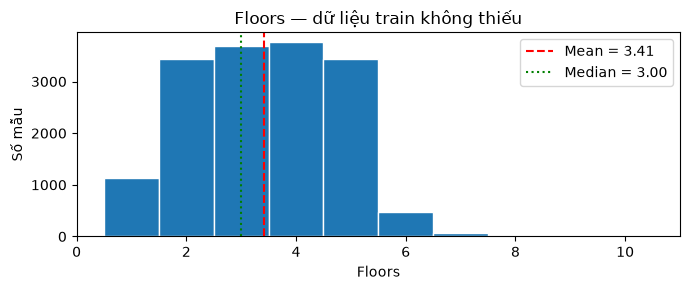

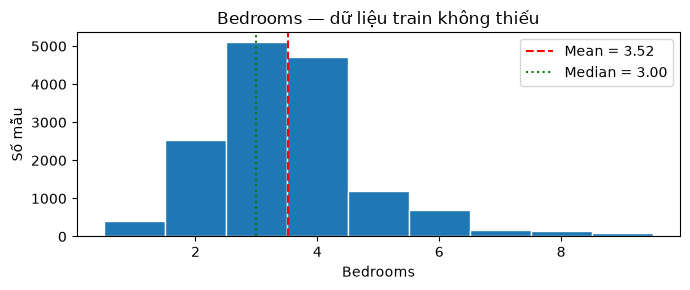

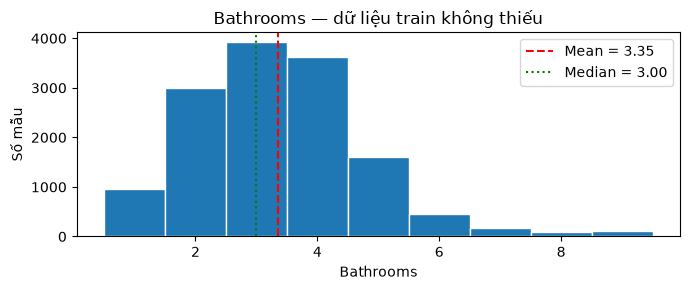

In [ ]:
# C10 — Kiểm tra các cột numeric có missing trên train

assert "X_train" in globals(), "Chạy C01–C03 trước."

missing_numeric_cols = [
    column
    for column in NUMERIC_FEATURES
    if X_train[column].isna().any()
]

print("Các cột numeric có missing:", missing_numeric_cols)

numeric_audit_rows = []

for column in missing_numeric_cols:
    observed = X_train[column].dropna()

    assert not observed.empty, f"{column}: toàn bộ giá trị bị thiếu."

    q1 = observed.quantile(0.25)
    q3 = observed.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outside_iqr = (
        (observed < lower_bound)
        | (observed > upper_bound)
    )

    numeric_audit_rows.append({
        "feature": column,
        "missing_count": int(X_train[column].isna().sum()),
        "missing_pct": X_train[column].isna().mean() * 100,
        "mean": observed.mean(),
        "median": observed.median(),
        "mean_minus_median": observed.mean() - observed.median(),
        "min": observed.min(),
        "max": observed.max(),
        "skewness": observed.skew(),
        "IQR": iqr,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outside_IQR_count": int(outside_iqr.sum()),
        # Tỷ lệ trên các giá trị quan sát được, không gồm missing.
        "outside_IQR_pct": outside_iqr.mean() * 100,
    })

numeric_imputation_audit = pd.DataFrame(numeric_audit_rows)
display(numeric_imputation_audit.round(4))

# Histogram để xem hình dạng phân phối.
for column in missing_numeric_cols:
    fig, ax = plt.subplots(figsize=(7, 3))

    observed = X_train[column].dropna()
    ax.hist(observed, bins=np.arange(observed.min() - 0.5, observed.max() + 1.5, 1), edgecolor="white")

    ax.axvline(
        observed.mean(),
        color="red",
        linestyle="--",
        label=f"Mean = {observed.mean():.2f}",
    )
    ax.axvline(
        observed.median(),
        color="green",
        linestyle=":",
        label=f"Median = {observed.median():.2f}",
    )

    ax.set_title(f"{column} — dữ liệu train không thiếu")
    ax.set_xlabel(column)
    ax.set_ylabel("Số mẫu")
    ax.legend()

    plt.tight_layout()
    plt.show()
plt.close("all")


In [ ]:
# C11 — Mean vs Median trên cùng RF đã chuẩn hóa
assert "normalized_rf" in globals(), "Chạy C09 trước."

imputation_models = {}
imputation_rows = []

for strategy in ["median", "mean"]:
    # Clone giữ cấu hình nhưng không giữ trạng thái đã fit.
    model = clone(normalized_rf)

    # Chỉ thay chiến lược điền missing của nhóm numeric.
    model.set_params(
        preprocessor__num__imputer__strategy=strategy
    )

    start = perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = perf_counter() - start

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    train_metrics = evaluate(y_train, train_pred)
    val_metrics = evaluate(y_val, val_pred)

    imputation_models[strategy] = model

    imputation_rows.append({
        "strategy": strategy,
        **{f"train_{k}": v for k, v in train_metrics.items()},
        **{f"val_{k}": v for k, v in val_metrics.items()},
        "MAE_gap": val_metrics["MAE"] - train_metrics["MAE"],
        "fit_seconds": fit_seconds,
    })

imputation_results = pd.DataFrame(imputation_rows)

median_mae = imputation_results.loc[
    imputation_results["strategy"].eq("median"),
    "val_MAE",
].iloc[0]

imputation_results["gain_vs_median_pct"] = (
    (median_mae - imputation_results["val_MAE"])
    / median_mae * 100
)

imputation_results.insert(0, "model", "RF_normalized")
display(imputation_results.round(6))

,model,strategy,train_MAE,train_RMSE,train_R2,val_MAE,val_RMSE,val_R2,MAE_gap,fit_seconds,gain_vs_median_pct
0,RF_normalized,median,0.400547,0.559537,0.936129,1.021221,1.379487,0.603180,0.620674,37.063796,0.000000
1,RF_normalized,mean,0.393470,0.540044,0.940501,1.018811,1.375232,0.605624,0.625340,36.290085,0.236052


In [ ]:
# C12 — Thêm missing indicators cho nhóm numeric
assert "imputation_models" in globals(), "Chạy C11 trước."
assert "mean" in imputation_models

mean_rf = imputation_models["mean"]

# Clone giữ cấu hình, không giữ trạng thái đã fit.
mean_indicator_rf = clone(mean_rf)

mean_indicator_rf.set_params(
    preprocessor__num__imputer__add_indicator=True
)

start = perf_counter()
mean_indicator_rf.fit(X_train, y_train)
indicator_fit_seconds = perf_counter() - start

# So sánh bằng dự đoán thực tế của hai model.
indicator_rows = []

for name, model in [
    ("RF_mean", mean_rf),
    ("RF_mean_with_indicator", mean_indicator_rf),
]:
    train_metrics = evaluate(
        y_train, model.predict(X_train)
    )
    val_metrics = evaluate(
        y_val, model.predict(X_val)
    )

    indicator_rows.append({
        "model": name,
        **{f"train_{k}": v for k, v in train_metrics.items()},
        **{f"val_{k}": v for k, v in val_metrics.items()},
        "MAE_gap": val_metrics["MAE"] - train_metrics["MAE"],
    })

indicator_results = pd.DataFrame(indicator_rows)

mean_mae = indicator_results.loc[
    indicator_results["model"].eq("RF_mean"),
    "val_MAE",
].iloc[0]

indicator_results["gain_vs_mean_pct"] = (
    (mean_mae - indicator_results["val_MAE"])
    / mean_mae * 100
)

display(indicator_results.round(6))

# Xem chính xác những cột nào được thêm indicator.
fitted_imputer = (
    mean_indicator_rf
    .named_steps["preprocessor"]
    .named_transformers_["num"]
    .named_steps["imputer"]
)

indicator_columns = [
    NUMERIC_FEATURES[index]
    for index in fitted_imputer.indicator_.features_
]

print("Các cột có missing indicator:", indicator_columns)
print(f"Thời gian fit phương án mới: {indicator_fit_seconds:.1f} giây")

,model,train_MAE,train_RMSE,train_R2,val_MAE,val_RMSE,val_R2,MAE_gap,gain_vs_mean_pct
0,RF_mean,0.393470,0.540044,0.940501,1.018811,1.375232,0.605624,0.625340,0.000000
1,RF_mean_with_indicator,0.395435,0.541878,0.940097,1.023610,1.380480,0.602609,0.628175,-0.471033


Các cột có missing indicator: ['Floors', 'Bedrooms', 'Bathrooms']
Thời gian fit phương án mới: 42.1 giây


In [ ]:
# C13 — So sánh Mean và KNN, cùng scaling trước imputation

assert "imputation_models" in globals(), "Chạy C11 trước."
assert "mean" in imputation_models

numeric_imputers = {
    "RF_scaled_mean": SimpleImputer(
        strategy="mean",
        add_indicator=False,
    ),
    "RF_scaled_KNN5": KNNImputer(
        n_neighbors=5,
        weights="uniform",
        add_indicator=False,
    ),
}

knn_experiment_models = {}
knn_experiment_rows = []

for name, imputer in numeric_imputers.items():
    print(f"Đang chạy: {name}", flush=True)

    model = clone(imputation_models["mean"])

    # Thay toàn bộ nhánh numeric:
    # scaling trước để KNN tính khoảng cách trên cùng thang đo.
    model.set_params(
        preprocessor__num=Pipeline([
            ("scaler", StandardScaler()),
            ("imputer", imputer),
        ])
    )

    start = perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = perf_counter() - start

    train_pred = model.predict(X_train)

    start = perf_counter()
    val_pred = model.predict(X_val)
    val_predict_seconds = perf_counter() - start

    train_metrics = evaluate(y_train, train_pred)
    val_metrics = evaluate(y_val, val_pred)

    knn_experiment_models[name] = model

    knn_experiment_rows.append({
        "model": name,
        **{f"train_{k}": v for k, v in train_metrics.items()},
        **{f"val_{k}": v for k, v in val_metrics.items()},
        "MAE_gap": val_metrics["MAE"] - train_metrics["MAE"],
        "fit_seconds": fit_seconds,
        "val_predict_seconds": val_predict_seconds,
    })

knn_results = pd.DataFrame(knn_experiment_rows)

control_mae = knn_results.loc[
    knn_results["model"].eq("RF_scaled_mean"),
    "val_MAE",
].iloc[0]

knn_results["gain_vs_mean_pct"] = (
    (control_mae - knn_results["val_MAE"])
    / control_mae * 100
)

display(knn_results.round(6))

Đang chạy: RF_scaled_mean
Đang chạy: RF_scaled_KNN5


,model,train_MAE,train_RMSE,train_R2,val_MAE,val_RMSE,val_R2,MAE_gap,fit_seconds,val_predict_seconds,gain_vs_mean_pct
0,RF_scaled_mean,0.392999,0.539736,0.940569,1.017520,1.374156,0.606241,0.624521,37.167242,0.134883,0.000000
1,RF_scaled_KNN5,0.399563,0.549295,0.938445,1.023708,1.378973,0.603476,0.624145,51.058627,2.575294,-0.608133


In [ ]:
# C14 — Chạy thêm KNN k=3 và k=15
assert "knn_results" in globals(), "Chạy C13 trước."
assert "knn_experiment_models" in globals(), "Chạy C13 trước."

new_knn_rows = []

for k in [3, 15]:
    name = f"RF_scaled_KNN{k}"
    print(f"Đang chạy: {name}", flush=True)

    model = clone(knn_experiment_models["RF_scaled_KNN5"])

    # Chỉ đổi số hàng xóm; giữ nguyên mọi thiết lập khác.
    model.set_params(
        preprocessor__num__imputer__n_neighbors=k
    )

    start = perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = perf_counter() - start

    train_pred = model.predict(X_train)

    start = perf_counter()
    val_pred = model.predict(X_val)
    val_predict_seconds = perf_counter() - start

    train_metrics = evaluate(y_train, train_pred)
    val_metrics = evaluate(y_val, val_pred)

    knn_experiment_models[name] = model

    new_knn_rows.append({
        "model": name,
        **{f"train_{metric}": value
           for metric, value in train_metrics.items()},
        **{f"val_{metric}": value
           for metric, value in val_metrics.items()},
        "MAE_gap": val_metrics["MAE"] - train_metrics["MAE"],
        "fit_seconds": fit_seconds,
        "val_predict_seconds": val_predict_seconds,
    })

# Lấy đúng hai kết quả đối chứng từ C13.
controls = knn_results.loc[
    knn_results["model"].isin([
        "RF_scaled_mean",
        "RF_scaled_KNN5",
    ])
].copy()

assert len(controls) == 2
assert controls["model"].is_unique

knn_k_results = pd.concat(
    [controls, pd.DataFrame(new_knn_rows)],
    ignore_index=True,
)

mean_mae = knn_k_results.loc[
    knn_k_results["model"].eq("RF_scaled_mean"),
    "val_MAE",
].iloc[0]

knn_k_results["gain_vs_mean_pct"] = (
    (mean_mae - knn_k_results["val_MAE"])
    / mean_mae * 100
)

knn_k_results = knn_k_results.sort_values(
    "val_MAE"
).reset_index(drop=True)

display(knn_k_results.round(6))

Đang chạy: RF_scaled_KNN3
Đang chạy: RF_scaled_KNN15


,model,train_MAE,train_RMSE,train_R2,val_MAE,val_RMSE,val_R2,MAE_gap,fit_seconds,val_predict_seconds,gain_vs_mean_pct
0,RF_scaled_mean,0.392999,0.539736,0.940569,1.017520,1.374156,0.606241,0.624521,37.167242,0.134883,0.000000
1,RF_scaled_KNN5,0.399563,0.549295,0.938445,1.023708,1.378973,0.603476,0.624145,51.058627,2.575294,-0.608133
2,RF_scaled_KNN15,0.397359,0.542969,0.939855,1.023828,1.378568,0.603708,0.626469,53.169951,1.795041,-0.619905
3,RF_scaled_KNN3,0.401193,0.552919,0.937631,1.025378,1.381036,0.602288,0.624185,67.176956,2.253920,-0.772250


In [ ]:
# C15 — Mode vs category "__MISSING__"
assert "knn_experiment_models" in globals(), "Chạy C13 trước."
assert "RF_scaled_mean" in knn_experiment_models

mode_rf = knn_experiment_models["RF_scaled_mean"]
MISSING_LABEL = "__MISSING__"

# Tránh dùng một nhãn đã tồn tại trong dữ liệu train.
for column in CATEGORICAL_FEATURES:
    assert not X_train[column].eq(MISSING_LABEL).fillna(False).any(), (
        f"{column}: nhãn {MISSING_LABEL} đã tồn tại."
    )

assert (
    mode_rf.get_params()["preprocessor__cat__imputer__strategy"]
    == "most_frequent"
), "Model đối chứng phải dùng mode cho categorical."

# Clone giữ cấu hình, không giữ trạng thái đã fit.
missing_category_rf = clone(mode_rf)

# Chỉ thay cách điền missing trong nhánh categorical.
missing_category_rf.set_params(
    preprocessor__cat__imputer__strategy="constant",
    preprocessor__cat__imputer__fill_value=MISSING_LABEL,
)

start = perf_counter()
missing_category_rf.fit(X_train, y_train)
missing_category_fit_seconds = perf_counter() - start

category_rows = []

for name, model in [
    ("RF_cat_mode", mode_rf),
    ("RF_cat_missing_label", missing_category_rf),
]:
    train_metrics = evaluate(
        y_train, model.predict(X_train)
    )
    val_metrics = evaluate(
        y_val, model.predict(X_val)
    )

    category_rows.append({
        "model": name,
        **{f"train_{k}": v for k, v in train_metrics.items()},
        **{f"val_{k}": v for k, v in val_metrics.items()},
        "MAE_gap": val_metrics["MAE"] - train_metrics["MAE"],
    })

category_results = pd.DataFrame(category_rows)

mode_mae = category_results.loc[
    category_results["model"].eq("RF_cat_mode"),
    "val_MAE",
].iloc[0]

category_results["gain_vs_mode_pct"] = (
    (mode_mae - category_results["val_MAE"])
    / mode_mae * 100
)

display(category_results.round(6))

# Kiểm tra encoder đã học category missing ở những cột nào.
fitted_encoder = (
    missing_category_rf
    .named_steps["preprocessor"]
    .named_transformers_["cat"]
    .named_steps["onehot"]
)

category_check = pd.DataFrame([
    {
        "feature": column,
        "missing_category_learned": MISSING_LABEL in categories,
        "encoded_categories": len(categories),
    }
    for column, categories in zip(
        CATEGORICAL_FEATURES,
        fitted_encoder.categories_,
    )
])

display(category_check)

print(
    "Thời gian fit phương án mới:",
    f"{missing_category_fit_seconds:.1f} giây",
)

,model,train_MAE,train_RMSE,train_R2,val_MAE,val_RMSE,val_R2,MAE_gap,gain_vs_mode_pct
0,RF_cat_mode,0.392999,0.539736,0.940569,1.017520,1.374156,0.606241,0.624521,0.000000
1,RF_cat_missing_label,0.388505,0.526996,0.943342,1.021881,1.374691,0.605935,0.633376,-0.428556


,feature,missing_category_learned,encoded_categories
0,House direction,True,9
1,Balcony direction,True,9
2,Legal status,True,3
3,Furniture state,True,3
4,City,True,69
5,District,True,295


Thời gian fit phương án mới: 5473.8 giây


## 4. Model tuyến tính — regularization

**C16:** chạy lại Linear Regression, bốn Ridge và sáu ElasticNet trên cùng preprocessing như RF_scaled_mean. Numeric được scaling; One-Hot giữ 0/1. Alpha giữa Ridge/ElasticNet không so trực tiếp về mức phạt.

Ghi nhận lịch sử: Ridge alpha=1 tốt nhất theo MAE (1.256151), chỉ cải thiện nhẹ so với LR (1.259860). ElasticNet giảm số hệ số nhưng chưa cải thiện MAE. Cấu hình mạnh làm train/validation cùng kém đi. Không có ConvergenceWarning không phải bằng chứng tổng quát model tối ưu; kiểm tra cảnh báo và giới hạn số bước khi phát sinh.

Số hệ số là số cột sau encoding, không phải 12 feature gốc. Giữ Ridge làm đại diện tuyến tính, chưa tạo tương tác/feature mới.

In [ ]:
# C16 — So sánh các model tuyến tính


assert "knn_experiment_models" in globals(), "Chạy C13 trước."
assert "RF_scaled_mean" in knn_experiment_models

rf_template = knn_experiment_models["RF_scaled_mean"]

# 1. Preprocessing chung, chỉ fit trên train.
linear_preprocessing = Pipeline([
    (name, clone(step))
    for name, step in rf_template.steps[:-1]
])

X_train_linear = linear_preprocessing.fit_transform(
    X_train, y_train
)
X_val_linear = linear_preprocessing.transform(X_val)

print("Train sau preprocessing:", X_train_linear.shape)
print("Validation sau preprocessing:", X_val_linear.shape)

# 2. Danh sách cấu hình.
linear_candidates = {
    "LinearRegression": LinearRegression(),
}

for alpha in [0.1, 1.0, 10.0, 100.0]:
    linear_candidates[f"Ridge_alpha_{alpha}"] = Ridge(
        alpha=alpha,
        solver="lsqr",
        tol=1e-6,
        max_iter=20000,
    )

for alpha in [0.001, 0.01, 0.1]:
    for l1_ratio in [0.2, 0.8]:
        name = f"ElasticNet_alpha_{alpha}_l1_{l1_ratio}"

        linear_candidates[name] = ElasticNet(
            alpha=alpha,
            l1_ratio=l1_ratio,
            max_iter=20000,
            tol=1e-4,
            selection="cyclic",
        )

# 3. Fit, đánh giá và lưu model.
linear_models = {}
linear_rows = []

for name, model in linear_candidates.items():
    print(f"Đang chạy: {name}", flush=True)

    start = perf_counter()

    with warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter("always")
        model.fit(X_train_linear, y_train)

    fit_seconds = perf_counter() - start

    convergence_warning = any(
        issubclass(w.category, ConvergenceWarning)
        for w in captured
    )

    # Hiển thị cảnh báo đã ghi nhận, không âm thầm bỏ qua.
    for warning in captured:
        print(f"  Cảnh báo: {warning.message}")

    train_metrics = evaluate(
        y_train, model.predict(X_train_linear)
    )
    val_metrics = evaluate(
        y_val, model.predict(X_val_linear)
    )

    coefficients = np.asarray(model.coef_).ravel()

    linear_models[name] = model

    linear_rows.append({
        "model": name,
        **{f"train_{k}": v for k, v in train_metrics.items()},
        **{f"val_{k}": v for k, v in val_metrics.items()},
        "MAE_gap": val_metrics["MAE"] - train_metrics["MAE"],
        "nonzero_coef": int(
            np.count_nonzero(np.abs(coefficients) > 1e-8)
        ),
        "total_coef": coefficients.size,
        "convergence_warning": convergence_warning,
        "fit_seconds": fit_seconds,
    })

linear_results = pd.DataFrame(linear_rows)

lr_mae = linear_results.loc[
    linear_results["model"].eq("LinearRegression"),
    "val_MAE",
].iloc[0]

linear_results["gain_vs_LR_pct"] = (
    (lr_mae - linear_results["val_MAE"])
    / lr_mae * 100
)

linear_results = linear_results.sort_values(
    "val_MAE"
).reset_index(drop=True)

display(linear_results.round(6))

if linear_results["convergence_warning"].any():
    print(
        "Có cấu hình phát cảnh báo hội tụ. "
        "Cần kiểm tra trước khi dùng kết quả để chọn model."
    )
# Pipeline riêng cho từng model tuyến tính, dùng được với X nguyên bản.
linear_pipelines = {
    name: Pipeline([
        ('preprocessing', deepcopy(linear_preprocessing)),
        ('model', fitted_model),
    ])
    for name, fitted_model in linear_models.items()
}


Train sau preprocessing: (18136, 388)
Validation sau preprocessing: (4535, 388)
Đang chạy: LinearRegression
Đang chạy: Ridge_alpha_0.1
Đang chạy: Ridge_alpha_1.0
Đang chạy: Ridge_alpha_10.0
Đang chạy: Ridge_alpha_100.0
Đang chạy: ElasticNet_alpha_0.001_l1_0.2
Đang chạy: ElasticNet_alpha_0.001_l1_0.8
Đang chạy: ElasticNet_alpha_0.01_l1_0.2
Đang chạy: ElasticNet_alpha_0.01_l1_0.8
Đang chạy: ElasticNet_alpha_0.1_l1_0.2
Đang chạy: ElasticNet_alpha_0.1_l1_0.8


,model,train_MAE,train_RMSE,train_R2,val_MAE,val_RMSE,val_R2,MAE_gap,nonzero_coef,total_coef,convergence_warning,fit_seconds,gain_vs_LR_pct
0,Ridge_alpha_1.0,1.242391,1.586702,0.486383,1.256151,1.623893,0.450113,0.013760,388,388,False,0.394975,0.294445
1,Ridge_alpha_0.1,1.235851,1.583146,0.488683,1.259107,1.634853,0.442666,0.023257,388,388,False,0.873932,0.059798
2,LinearRegression,1.234645,1.583032,0.488756,1.259860,1.637434,0.440905,0.025215,388,388,False,0.836736,0.000000
3,Ridge_alpha_10.0,1.264111,1.609831,0.471300,1.263024,1.622486,0.451066,-0.001087,388,388,False,0.195396,-0.251111
4,ElasticNet_alpha_0.001_l1_0.8,1.278947,1.628759,0.458795,1.271163,1.629393,0.446382,-0.007784,127,388,False,0.349382,-0.897156
5,ElasticNet_alpha_0.001_l1_0.2,1.276807,1.624124,0.461870,1.271271,1.629552,0.446274,-0.005536,232,388,False,0.468756,-0.905725
6,Ridge_alpha_100.0,1.331765,1.678473,0.425252,1.318768,1.674729,0.415146,-0.012997,388,388,False,0.088440,-4.675724
7,ElasticNet_alpha_0.01_l1_0.2,1.375126,1.723830,0.393770,1.355842,1.712011,0.388817,-0.019284,87,388,False,0.104124,-7.618395
8,ElasticNet_alpha_0.01_l1_0.8,1.405377,1.758251,0.369318,1.383918,1.743261,0.366301,-0.021459,39,388,False,0.169929,-9.846949
9,ElasticNet_alpha_0.1_l1_0.2,1.547090,1.896856,0.265964,1.523188,1.872833,0.268597,-0.023902,25,388,False,0.087883,-20.901323


## 5. Boosting — CatBoost, XGBoost, LightGBM

| Cell | Experiment | Preprocessing / ghi nhận lịch sử |
|---|---|---|
| C17 | CatBoost 1500 vòng | Numeric median, categorical mode và native categorical; MAE 0.999866 |
| C18 | CatBoost 3000 vòng | Giữ nguyên C17; best 2973, MAE 0.990914 |
| C19 | XGBoost 3000 vòng | Preprocessing RF_scaled_mean; best 2993, MAE 0.980569 |
| C20 | LightGBM 3000 vòng | Cùng ma trận đầu vào C19; best 1527, MAE 0.986465 |

Đây là so sánh pipeline ứng viên, **chưa phải ablation chỉ đổi thuật toán**: CatBoost giữ median/native categorical để bảo toàn experiment cũ. XGBoost và LightGBM dùng One-Hot; thư viện có thể xử lý phần tử không lưu trong sparse khác nhau. Không suy ra cùng ma trận nghĩa là cùng cơ chế học.

Validation dùng cho early stopping/chọn vòng; chưa phải đánh giá cuối. Số vòng chạy khác số vòng tốt nhất. RMSE và R² cùng dựa trên bình phương lỗi; không xem là hai phiếu độc lập chống lại MAE. Thời gian là lần đo thực tế, chưa phải benchmark kiểm soát.

Các pipeline XGBoost/LightGBM được ghép từ thành phần đã fit để predict; không fit lại trực tiếp pipeline ghép khi dùng eval_set thô. Preprocessing được sao chép độc lập để tránh model này thay đổi trạng thái model khác.

In [ ]:
# C17 — CatBoost đầu tiên, so sánh với RF sau chuẩn hóa

assert "normalized_rf" in globals(), "Chạy C09 trước."

print("CatBoost version:", catboost.__version__)

# 1. Chuẩn hóa tên trên bản sao, không sửa dữ liệu gốc.
cb_train = normalize_location_frame(X_train)
cb_val = normalize_location_frame(X_val)

# 2. Học giá trị điền thiếu chỉ từ train.
cb_numeric_imputer = SimpleImputer(strategy="median")
cb_category_imputer = SimpleImputer(strategy="most_frequent")

assert cb_train[NUMERIC_FEATURES].notna().any().all()
assert cb_train[CATEGORICAL_FEATURES].notna().any().all()

cb_train[NUMERIC_FEATURES] = cb_numeric_imputer.fit_transform(
    cb_train[NUMERIC_FEATURES]
)
cb_val[NUMERIC_FEATURES] = cb_numeric_imputer.transform(
    cb_val[NUMERIC_FEATURES]
)

cb_train[CATEGORICAL_FEATURES] = (
    cb_category_imputer.fit_transform(
        cb_train[CATEGORICAL_FEATURES]
    )
)
cb_val[CATEGORICAL_FEATURES] = cb_category_imputer.transform(
    cb_val[CATEGORICAL_FEATURES]
)

# CatBoost nhận categorical dạng chuỗi, không còn missing.
for column in CATEGORICAL_FEATURES:
    assert cb_train[column].notna().all()
    assert cb_val[column].notna().all()

    cb_train[column] = cb_train[column].astype(str)
    cb_val[column] = cb_val[column].astype(str)

assert list(cb_train.columns) == list(cb_val.columns)
assert cb_train.index.equals(y_train.index)
assert cb_val.index.equals(y_val.index)

# 3. Một cấu hình khởi đầu.
catboost_model = CatBoostRegressor(
    iterations=1500,
    depth=6,
    learning_rate=0.05,
    loss_function="RMSE",
    eval_metric="MAE",
    random_seed=42,
    task_type="CPU",
    allow_writing_files=False,
)

start = perf_counter()

catboost_model.fit(
    cb_train,
    y_train,
    cat_features=CATEGORICAL_FEATURES,
    eval_set=(cb_val, y_val),
    early_stopping_rounds=100,
    use_best_model=True,
    verbose=200,
)

cb_fit_seconds = perf_counter() - start

# 4. Dự đoán và đánh giá.
cb_train_pred = catboost_model.predict(cb_train)
cb_val_pred = catboost_model.predict(cb_val)

rf_train_pred = normalized_rf.predict(X_train)
rf_val_pred = normalized_rf.predict(X_val)

model_comparison_rows = []

for name, train_pred, val_pred in [
    ("RF_normalized", rf_train_pred, rf_val_pred),
    ("CatBoost_initial", cb_train_pred, cb_val_pred),
]:
    train_metrics = evaluate(y_train, train_pred)
    val_metrics = evaluate(y_val, val_pred)

    model_comparison_rows.append({
        "model": name,
        **{f"train_{k}": v for k, v in train_metrics.items()},
        **{f"val_{k}": v for k, v in val_metrics.items()},
        "MAE_gap": val_metrics["MAE"] - train_metrics["MAE"],
    })

boosting_comparison = pd.DataFrame(model_comparison_rows)

rf_mae = boosting_comparison.loc[
    boosting_comparison["model"].eq("RF_normalized"),
    "val_MAE",
].iloc[0]

boosting_comparison["gain_vs_RF_pct"] = (
    (rf_mae - boosting_comparison["val_MAE"])
    / rf_mae * 100
)

print("\nSo sánh model — MAE/RMSE dùng tỷ VND:")
display(boosting_comparison.round(6))

print("Số cây được giữ:", catboost_model.tree_count_)
print(
    "Vòng tốt nhất (đếm từ 1):",
    catboost_model.get_best_iteration() + 1,
)
print(f"Thời gian fit CatBoost: {cb_fit_seconds:.1f} giây")

CatBoost version: 1.2.10
0:	learn: 1.8137331	test: 1.7926366	best: 1.7926366 (0)	total: 137ms	remaining: 3m 26s
200:	learn: 1.1002966	test: 1.0774834	best: 1.0774834 (200)	total: 12.6s	remaining: 1m 21s
400:	learn: 1.0385813	test: 1.0388183	best: 1.0388183 (400)	total: 21.7s	remaining: 59.5s
600:	learn: 1.0087966	test: 1.0261355	best: 1.0261355 (600)	total: 30.4s	remaining: 45.5s
800:	learn: 0.9848901	test: 1.0168011	best: 1.0168011 (800)	total: 39.6s	remaining: 34.5s
1000:	learn: 0.9632187	test: 1.0092992	best: 1.0092992 (1000)	total: 48.7s	remaining: 24.3s
1200:	learn: 0.9470061	test: 1.0051339	best: 1.0049545 (1188)	total: 57.9s	remaining: 14.4s
1400:	learn: 0.9329536	test: 1.0021219	best: 1.0021219 (1400)	total: 1m 9s	remaining: 4.92s
1499:	learn: 0.9252710	test: 0.9998655	best: 0.9998655 (1499)	total: 1m 15s	remaining: 0us

bestTest = 0.9998654507
bestIteration = 1499


So sánh model — MAE/RMSE dùng tỷ VND:


,model,train_MAE,train_RMSE,train_R2,val_MAE,val_RMSE,val_R2,MAE_gap,gain_vs_RF_pct
0,RF_normalized,0.400547,0.559537,0.936129,1.021221,1.379487,0.603180,0.620674,0.0000
1,CatBoost_initial,0.931441,1.220773,0.695968,0.999866,1.324894,0.633967,0.068426,2.0911


Số cây được giữ: 1500
Vòng tốt nhất (đếm từ 1): 1500
Thời gian fit CatBoost: 75.9 giây


In [ ]:
# C18 — CatBoost: tối đa 3000 vòng
assert "catboost_model" in globals(), "Chạy C17 trước."
assert "cb_train" in globals() and "cb_val" in globals()

# Lấy đúng cấu hình của model khởi đầu.
extended_params = catboost_model.get_params().copy()
assert extended_params["iterations"] == 1500

extended_params["iterations"] = 3000

# Model mới; giữ nguyên model 1500 vòng để đối chiếu.
catboost_3000 = CatBoostRegressor(**extended_params)

start = perf_counter()

catboost_3000.fit(
    cb_train,
    y_train,
    cat_features=CATEGORICAL_FEATURES,
    eval_set=(cb_val, y_val),
    early_stopping_rounds=100,
    use_best_model=True,
    verbose=300,
)

cb_3000_fit_seconds = perf_counter() - start

iteration_rows = []

for name, model in [
    ("CatBoost_max1500", catboost_model),
    ("CatBoost_max3000", catboost_3000),
]:
    train_metrics = evaluate(
        y_train, model.predict(cb_train)
    )
    val_metrics = evaluate(
        y_val, model.predict(cb_val)
    )

    iteration_rows.append({
        "model": name,
        "iteration_limit": model.get_params()["iterations"],
        "trees_kept": model.tree_count_,
        "best_iteration": model.get_best_iteration() + 1,
        **{f"train_{k}": v for k, v in train_metrics.items()},
        **{f"val_{k}": v for k, v in val_metrics.items()},
        "MAE_gap": val_metrics["MAE"] - train_metrics["MAE"],
    })

catboost_iteration_results = pd.DataFrame(iteration_rows)

initial_mae = catboost_iteration_results.loc[
    catboost_iteration_results["model"].eq("CatBoost_max1500"),
    "val_MAE",
].iloc[0]

catboost_iteration_results["gain_vs_1500_pct"] = (
    (initial_mae - catboost_iteration_results["val_MAE"])
    / initial_mae * 100
)

display(catboost_iteration_results.round(6))

print(f"Thời gian fit model mới: {cb_3000_fit_seconds:.1f} giây")

0:	learn: 1.8137331	test: 1.7926366	best: 1.7926366 (0)	total: 83.2ms	remaining: 4m 9s
300:	learn: 1.0639279	test: 1.0529682	best: 1.0529526 (299)	total: 17.7s	remaining: 2m 38s
600:	learn: 1.0087966	test: 1.0261355	best: 1.0261355 (600)	total: 35s	remaining: 2m 19s
900:	learn: 0.9730165	test: 1.0123930	best: 1.0123719 (899)	total: 52.5s	remaining: 2m 2s
1200:	learn: 0.9470061	test: 1.0051339	best: 1.0049545 (1188)	total: 1m 9s	remaining: 1m 43s
1500:	learn: 0.9252049	test: 0.9998455	best: 0.9998455 (1500)	total: 1m 26s	remaining: 1m 25s
1800:	learn: 0.9061168	test: 0.9964709	best: 0.9964578 (1799)	total: 1m 41s	remaining: 1m 7s
2100:	learn: 0.8895327	test: 0.9943927	best: 0.9943927 (2100)	total: 1m 56s	remaining: 49.8s
2400:	learn: 0.8756274	test: 0.9936895	best: 0.9936895 (2400)	total: 2m 9s	remaining: 32.4s
2700:	learn: 0.8624430	test: 0.9926211	best: 0.9926211 (2700)	total: 2m 22s	remaining: 15.8s
2999:	learn: 0.8502600	test: 0.9909867	best: 0.9909135 (2972)	total: 2m 34s	remaining

,model,iteration_limit,trees_kept,best_iteration,train_MAE,train_RMSE,train_R2,val_MAE,val_RMSE,val_R2,MAE_gap,gain_vs_1500_pct
0,CatBoost_max1500,1500,1500,1500,0.931441,1.220773,0.695968,0.999866,1.324894,0.633967,0.068426,0.000000
1,CatBoost_max3000,3000,2973,2973,0.884386,1.163647,0.723757,0.990914,1.315498,0.639140,0.106529,0.895317


Thời gian fit model mới: 155.5 giây


In [ ]:
# C19 — XGBoost khởi đầu

assert "knn_experiment_models" in globals(), "Chạy C13 trước."
assert "catboost_3000" in globals(), "Chạy C18 trước."

print("XGBoost version:", xgboost.__version__)

rf_reference = knn_experiment_models["RF_scaled_mean"]

# 1. Clone các bước preprocessing từ RF, không lấy model RF.
xgb_preprocessing = Pipeline([
    (name, clone(step))
    for name, step in rf_reference.steps[:-1]
])

start = perf_counter()

X_train_xgb = xgb_preprocessing.fit_transform(X_train, y_train)
X_val_xgb = xgb_preprocessing.transform(X_val)

xgb_preprocessing_seconds = perf_counter() - start

print("Train sau preprocessing:", X_train_xgb.shape)
print("Validation sau preprocessing:", X_val_xgb.shape)

# 2. Một cấu hình khởi đầu.
xgb_model = XGBRegressor(
    n_estimators=3000,
    max_depth=6,
    learning_rate=0.05,
    objective="reg:squarederror",
    eval_metric="mae",
    tree_method="hist",
    subsample=1.0,
    colsample_bytree=1.0,
    random_state=42,
    n_jobs=-1,
    early_stopping_rounds=100,
)

start = perf_counter()

xgb_model.fit(
    X_train_xgb,
    y_train,
    eval_set=[(X_val_xgb, y_val)],
    verbose=300,
)

xgb_fit_seconds = perf_counter() - start

# 3. Ghép lại để predict trực tiếp từ X chưa preprocessing.
# Hai thành phần đều đã fit. Không gọi fit lại pipeline này.
xgb_pipeline = Pipeline([
    ("preprocessing", deepcopy(xgb_preprocessing)),
    ("model", xgb_model),
])

# 4. So sánh bằng dự đoán thực tế.
comparison_inputs = [
    (
        "RF_scaled_mean",
        rf_reference.predict(X_train),
        rf_reference.predict(X_val),
    ),
    (
        "CatBoost_max3000",
        catboost_3000.predict(cb_train),
        catboost_3000.predict(cb_val),
    ),
    (
        "XGBoost_initial",
        xgb_pipeline.predict(X_train),
        xgb_pipeline.predict(X_val),
    ),
]

exploration_rows = []

for name, train_pred, val_pred in comparison_inputs:
    train_metrics = evaluate(y_train, train_pred)
    val_metrics = evaluate(y_val, val_pred)

    exploration_rows.append({
        "model": name,
        **{f"train_{k}": v for k, v in train_metrics.items()},
        **{f"val_{k}": v for k, v in val_metrics.items()},
        "MAE_gap": val_metrics["MAE"] - train_metrics["MAE"],
    })

model_exploration_results = pd.DataFrame(exploration_rows)

rf_mae = model_exploration_results.loc[
    model_exploration_results["model"].eq("RF_scaled_mean"),
    "val_MAE",
].iloc[0]

model_exploration_results["gain_vs_RF_pct"] = (
    (rf_mae - model_exploration_results["val_MAE"])
    / rf_mae * 100
)

display(
    model_exploration_results
    .sort_values("val_MAE")
    .reset_index(drop=True)
    .round(6)
)

rounds_run = len(
    xgb_model.evals_result()["validation_0"]["mae"]
)

print("Số vòng đã chạy:", rounds_run)
print("Vòng tốt nhất:", xgb_model.best_iteration + 1)
print(f"Thời gian preprocessing: {xgb_preprocessing_seconds:.1f} giây")
print(f"Thời gian fit XGBoost: {xgb_fit_seconds:.1f} giây")

XGBoost version: 3.4.1
Train sau preprocessing: (18136, 388)
Validation sau preprocessing: (4535, 388)
[0]	validation_0-mae:1.78817
[300]	validation_0-mae:1.05047
[600]	validation_0-mae:1.01442
[900]	validation_0-mae:1.00072
[1200]	validation_0-mae:0.99304
[1500]	validation_0-mae:0.98972
[1800]	validation_0-mae:0.98647
[2100]	validation_0-mae:0.98494
[2400]	validation_0-mae:0.98372
[2700]	validation_0-mae:0.98215
[2999]	validation_0-mae:0.98060


,model,train_MAE,train_RMSE,train_R2,val_MAE,val_RMSE,val_R2,MAE_gap,gain_vs_RF_pct
0,XGBoost_initial,0.700953,0.950592,0.815653,0.980569,1.327245,0.632667,0.279617,3.631465
1,CatBoost_max3000,0.884386,1.163647,0.723757,0.990914,1.315498,0.639140,0.106529,2.614769
2,RF_scaled_mean,0.392999,0.539736,0.940569,1.017520,1.374156,0.606241,0.624521,0.000000


Số vòng đã chạy: 3000
Vòng tốt nhất: 2993
Thời gian preprocessing: 0.2 giây
Thời gian fit XGBoost: 75.9 giây


In [ ]:
# C20 — LightGBM khởi đầu

assert "X_train_xgb" in globals(), "Chạy C19 trước."
assert "X_val_xgb" in globals(), "Chạy C19 trước."
assert "xgb_pipeline" in globals(), "Chạy C19 trước."
assert "catboost_3000" in globals(), "Chạy C18 trước."

print("LightGBM version:", lgb.__version__)

# Dùng nguyên ma trận đầu vào của experiment XGBoost.
X_train_lgb = X_train_xgb
X_val_lgb = X_val_xgb

assert X_train_lgb.shape[0] == len(y_train)
assert X_val_lgb.shape[0] == len(y_val)
assert X_train_lgb.shape[1] == X_val_lgb.shape[1]

lgb_model = lgb.LGBMRegressor(
    objective="regression",
    metric="mae",
    n_estimators=3000,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=6,
    min_child_samples=20,
    subsample=1.0,
    colsample_bytree=1.0,
    random_state=42,
    n_jobs=-1,
    verbosity=-1,
)

start = perf_counter()

lgb_model.fit(
    X_train_lgb,
    y_train,
    eval_set=[(X_val_lgb, y_val)],
    eval_names=["validation"],
    callbacks=[
        lgb.early_stopping(
            stopping_rounds=100,
            first_metric_only=True,
            verbose=True,
        ),
        lgb.log_evaluation(period=300),
    ],
)

lgb_fit_seconds = perf_counter() - start

# Lưu preprocessing đã fit cùng model để predict từ X gốc.
# Không gọi fit lại pipeline này.
lgb_pipeline = Pipeline([
    ("preprocessing", deepcopy(xgb_preprocessing)),
    ("model", lgb_model),
])

# Bản sao preprocessing đã fit thuộc riêng pipeline này; không chia sẻ trạng thái với XGBoost.

rf_reference = knn_experiment_models["RF_scaled_mean"]

comparison_inputs = [
    (
        "RF_scaled_mean",
        rf_reference.predict(X_train),
        rf_reference.predict(X_val),
    ),
    (
        "CatBoost_max3000",
        catboost_3000.predict(cb_train),
        catboost_3000.predict(cb_val),
    ),
    (
        "XGBoost_initial",
        xgb_pipeline.predict(X_train),
        xgb_pipeline.predict(X_val),
    ),
    (
        "LightGBM_initial",
        lgb_pipeline.predict(X_train),
        lgb_pipeline.predict(X_val),
    ),
]

comparison_rows = []

for name, train_pred, val_pred in comparison_inputs:
    train_metrics = evaluate(y_train, train_pred)
    val_metrics = evaluate(y_val, val_pred)

    comparison_rows.append({
        "model": name,
        **{f"train_{k}": v for k, v in train_metrics.items()},
        **{f"val_{k}": v for k, v in val_metrics.items()},
        "MAE_gap": val_metrics["MAE"] - train_metrics["MAE"],
    })

boosting_results = pd.DataFrame(comparison_rows)

rf_mae = boosting_results.loc[
    boosting_results["model"].eq("RF_scaled_mean"),
    "val_MAE",
].iloc[0]

boosting_results["gain_vs_RF_pct"] = (
    (rf_mae - boosting_results["val_MAE"])
    / rf_mae * 100
)

display(
    boosting_results
    .sort_values("val_MAE")
    .reset_index(drop=True)
    .round(6)
)

# Đếm số vòng đã được ghi vào lịch sử đánh giá.
validation_history = lgb_model.evals_result_["validation"]
rounds_run = len(next(iter(validation_history.values())))

print("Số vòng đã chạy:", rounds_run)
print("Vòng tốt nhất:", lgb_model.best_iteration_)
print(f"Thời gian fit LightGBM: {lgb_fit_seconds:.1f} giây")

LightGBM version: 4.7.0
Training until validation scores don't improve for 100 rounds

d:\MinhTriet\LT\AIQS\AIQS-Real-Estate-Price-Prediction\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)



[300]	validation's l1: 1.0457
[600]	validation's l1: 1.00713
[900]	validation's l1: 0.994999
[1200]	validation's l1: 0.989191
[1500]	validation's l1: 0.986803
Early stopping, best iteration is:
[1527]	validation's l1: 0.986465
Evaluated only: l1


,model,train_MAE,train_RMSE,train_R2,val_MAE,val_RMSE,val_R2,MAE_gap,gain_vs_RF_pct
0,XGBoost_initial,0.700953,0.950592,0.815653,0.980569,1.327245,0.632667,0.279617,3.631465
1,LightGBM_initial,0.839405,1.112113,0.747683,0.986465,1.320170,0.636572,0.147060,3.052067
2,CatBoost_max3000,0.884386,1.163647,0.723757,0.990914,1.315498,0.639140,0.106529,2.614769
3,RF_scaled_mean,0.392999,0.539736,0.940569,1.017520,1.374156,0.606241,0.624521,0.000000


Số vòng đã chạy: 1627
Vòng tốt nhất: 1527
Thời gian fit LightGBM: 3.2 giây


## 6. Tổng hợp và điểm dừng

**C21** ghép metric thực tế từ các bảng vừa tính, không nhập cứng. Bảng gồm RF gốc, RF chuẩn hóa, RF mean hiện tại, LR/Ridge/ElasticNet và các boosting. Chỉ xét ứng viên tuyến tính không phát ConvergenceWarning; phải đối chiếu kết quả trước khi chốt. Tất cả là validation, không phải test.

In [ ]:
# C21 — Tổng hợp model từ kết quả thực tế
summary_parts = []

def add_summary(frame, preprocessing_label):
    columns = ['model', 'train_MAE', 'train_RMSE', 'train_R2',
               'val_MAE', 'val_RMSE', 'val_R2', 'MAE_gap']
    part = frame[columns].copy()
    part['preprocessing'] = preprocessing_label
    summary_parts.append(part)

rf_original = results_exp01.loc[results_exp01['experiment'].eq('RF_baseline')].rename(columns={'experiment':'model'})
add_summary(rf_original, 'Original location; median → scaling; categorical mode/OHE')
rf_normalized = normalization_results.loc[normalization_results['experiment'].eq('RF_after_normalization')].rename(columns={'experiment':'model'})
add_summary(rf_normalized, 'Normalized location; median → scaling; categorical mode/OHE')
add_summary(knn_results.loc[knn_results['model'].eq('RF_scaled_mean')], 'Normalized location; scaling → mean; categorical mode/OHE')

eligible_linear = linear_results.loc[~linear_results['convergence_warning']].copy()
assert not eligible_linear.empty, 'Chưa có ứng viên tuyến tính hợp lệ để tổng hợp.'
add_summary(eligible_linear, 'Normalized location; scaling → mean; categorical mode/OHE')
add_summary(catboost_iteration_results, 'Normalized location; numeric median; categorical mode/native')
add_summary(boosting_results.loc[boosting_results['model'].isin(['XGBoost_initial','LightGBM_initial'])], 'Normalized location; scaling → mean; categorical mode/OHE')

final_model_summary = pd.concat(summary_parts, ignore_index=True)
assert final_model_summary['model'].is_unique
assert np.isfinite(final_model_summary.select_dtypes(include='number').to_numpy()).all()
final_model_summary = final_model_summary.sort_values('val_MAE').reset_index(drop=True)
display(final_model_summary.round(6))
print('Dẫn đầu MAE validation trong lần chạy này:', final_model_summary.iloc[0]['model'])
print('Chưa chốt model cuối; calibration/test chưa được dùng.')


,model,train_MAE,train_RMSE,train_R2,val_MAE,val_RMSE,val_R2,MAE_gap,preprocessing
0,XGBoost_initial,0.700953,0.950592,0.815653,0.980569,1.327245,0.632667,0.279617,Normalized location; scaling → mean; categoric...
1,LightGBM_initial,0.839405,1.112113,0.747683,0.986465,1.320170,0.636572,0.147060,Normalized location; scaling → mean; categoric...
2,CatBoost_max3000,0.884386,1.163647,0.723757,0.990914,1.315498,0.639140,0.106529,Normalized location; numeric median; categoric...
3,CatBoost_max1500,0.931441,1.220773,0.695968,0.999866,1.324894,0.633967,0.068426,Normalized location; numeric median; categoric...
4,RF_scaled_mean,0.392999,0.539736,0.940569,1.017520,1.374156,0.606241,0.624521,Normalized location; scaling → mean; categoric...
5,RF_after_normalization,0.400547,0.559537,0.936129,1.021221,1.379487,0.603180,0.620674,Normalized location; median → scaling; categor...
6,RF_baseline,0.403141,0.564637,0.934959,1.023930,1.388079,0.598222,0.620790,Original location; median → scaling; categoric...
7,Ridge_alpha_1.0,1.242391,1.586702,0.486383,1.256151,1.623893,0.450113,0.013760,Normalized location; scaling → mean; categoric...
8,Ridge_alpha_0.1,1.235851,1.583146,0.488683,1.259107,1.634853,0.442666,0.023257,Normalized location; scaling → mean; categoric...
9,LinearRegression,1.234645,1.583032,0.488756,1.259860,1.637434,0.440905,0.025215,Normalized location; scaling → mean; categoric...


Dẫn đầu MAE validation trong lần chạy này: XGBoost_initial
Chưa chốt model cuối; calibration/test chưa được dùng.


## 7. Roadmap sau model exploration

1. Đọc bảng C21 và đối chiếu các kết luận lịch sử; không tự chuyển kết quả RF thành lựa chọn preprocessing cho mọi model.
2. Thử preprocessing/feature engineering trên vài model đại diện; experiment đầu dự kiến City_District, chưa triển khai.
3. Cross-validation với preprocessing fit riêng trong từng fold, rồi tuning có giới hạn và explainability.
4. Ensemble đơn giản nếu có lý do; Deep Learning để nhánh nâng cao sau.
5. Chốt model trước notebook 04: refit, calibration interval, test, lưu/load và inference.

Chưa có feature engineering City_District, CV, SHAP hoặc final test trong notebook hiện tại. Không coi R² train hoặc validation là nghiệm thu test.

**Cập nhật:** RF được bổ sung tuning có hệ thống tại C22–C25 bên dưới. Các experiment C04–C06 là thăm dò thủ công, chưa phải bằng chứng RF đã được tối ưu.


## 8. RF Grid Search — lượt 1

**Giả thuyết:** các tham số RF tương tác với nhau; thăm dò từng nhóm trước đây có thể bỏ sót vùng tốt. Lượt này tìm đồng thời trên 144 cấu hình, 3-fold CV cố định chỉ trong train (432 fit, thêm 1 refit cấu hình được chọn).

Giữ preprocessing RF_scaled_mean: chuẩn hóa địa phương → numeric scaling rồi mean imputation; categorical mode rồi One-Hot. Pipeline fit mới trong từng fold. Giữ seed model=42 và n_estimators=100. Một cấp song song: Grid Search chạy tuần tự các fit, RF dùng nhiều CPU cho các cây.

MAE trung bình CV là tiêu chí chọn. RMSE, R², độ lệch chuẩn qua fold, gap và thời gian giúp đọc kết quả. Độ lệch chuẩn 3 fold không phải khoảng tin cậy. CV đang dùng để lựa chọn nên score của cấu hình thắng có thể lạc quan; validation/test không được dùng trong bốn cell này.

Chạy C22–C23 trước để kiểm tra và đo chi phí. C24 là lượt chạy dài; khi xong tự lưu kết quả và thiết lập vào experiments/rf_grid_search. C25 đọc kết quả để quyết định phạm vi lượt 2, chưa tự chốt model cuối. Nếu dừng C24 giữa chừng, GridSearchCV không tự resume các fit đã hoàn thành.


In [ ]:
# C22 — Khai báo grid RF (không train)
assert "rf_cv_splits" in globals(), "Chạy S01 trước."
rf_param_grid = {
    "model__max_depth": [None, 15, 25, 35],
    "model__min_samples_leaf": [1, 2, 5],
    "model__max_features": [0.3, 0.5, 0.7, 1.0],
    "model__min_samples_split": [2, 5, 10],
}
rf_scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2",
}
rf_n_candidates = len(ParameterGrid(rf_param_grid))
assert rf_n_candidates == 144
print(f"{rf_n_candidates} cấu hình × {len(rf_cv_splits)} fold = 432 fit + 1 refit.")
print("Không dùng validation, calibration hoặc test trong bước này.")


144 cấu hình × 3 fold = 432 fit + 1 refit.
Không dùng validation, calibration hoặc test trong bước này.


In [ ]:
# C23 — RF hiện tại trên cùng CV và đo thời gian
assert "rf_cv_splits" in globals(), "Chạy C22 trước."
start = perf_counter()
rf_control_cv = cross_validate(
    rf_grid_pipeline, X_train, y_train,
    cv=rf_cv_splits, scoring=rf_scoring,
    n_jobs=1, return_train_score=True, error_score="raise",
)
rf_control_seconds = perf_counter() - start
rf_control_folds = pd.DataFrame({
    "fold": np.arange(1, len(rf_cv_splits) + 1),
    "train_MAE": -rf_control_cv["train_MAE"],
    "cv_MAE": -rf_control_cv["test_MAE"],
    "cv_RMSE": -rf_control_cv["test_RMSE"],
    "cv_R2": rf_control_cv["test_R2"],
    "fit_seconds": rf_control_cv["fit_time"],
})
rf_control_folds["MAE_gap"] = rf_control_folds["cv_MAE"] - rf_control_folds["train_MAE"]
display(rf_control_folds.round(6))
print(f"Đối chứng CV MAE: {rf_control_folds['cv_MAE'].mean():.6f} tỷ VND")
print(f"Thời gian 3 fold: {rf_control_seconds:.1f} giây")
print(f"Ước tính nếu mọi cấu hình tốn như đối chứng: {rf_control_seconds * rf_n_candidates / 3600:.2f} giờ, chưa tính refit.")
print("Đây là ước tính thô: depth/leaf/max_features làm thời gian mỗi cấu hình khác nhau.")


,fold,train_MAE,cv_MAE,cv_RMSE,cv_R2,fit_seconds,MAE_gap
0,1,0.406436,1.056296,1.399053,0.599420,20.648609,0.649860
1,2,0.399649,1.057399,1.404995,0.589916,19.327615,0.657750
2,3,0.405401,1.057543,1.424279,0.594521,19.999748,0.652142


Đối chứng CV MAE: 1.057079 tỷ VND
Thời gian 3 fold: 61.2 giây
Ước tính nếu mọi cấu hình tốn như đối chứng: 2.45 giờ, chưa tính refit.
Đây là ước tính thô: depth/leaf/max_features làm thời gian mỗi cấu hình khác nhau.


In [ ]:
# C24 — Chạy Grid Search lượt 1 (cell chạy dài)
assert "rf_control_cv" in globals(), "Chạy C23 trước."
rf_grid_search = GridSearchCV(
    estimator=rf_grid_pipeline,
    param_grid=rf_param_grid,
    scoring=rf_scoring,
    refit="MAE",
    cv=rf_cv_splits,
    n_jobs=1,
    return_train_score=True,
    error_score="raise",
    verbose=2,
)
start = perf_counter()
rf_grid_search.fit(X_train, y_train)
rf_grid_seconds = perf_counter() - start
rf_grid_raw_results = pd.DataFrame(rf_grid_search.cv_results_)
assert len(rf_grid_raw_results) == rf_n_candidates
assert np.isfinite(rf_grid_raw_results["mean_test_MAE"]).all()

RF_SEARCH_DIR = PROJECT_ROOT / "experiments" / "rf_grid_search"
RF_SEARCH_DIR.mkdir(parents=True, exist_ok=True)
rf_grid_raw_results.to_csv(RF_SEARCH_DIR / "round1_cv_results.csv", index=False)
rf_control_folds.to_csv(RF_SEARCH_DIR / "round1_control_cv.csv", index=False)
rf_search_manifest = {
    "selection_metric": "mean CV MAE (billion VND)",
    "cv": {"n_splits": 3, "shuffle": True, "random_state": 42},
    "model_seed": 42,
    "n_estimators": 100,
    "param_grid": rf_param_grid,
    "best_params": rf_grid_search.best_params_,
    "best_cv_MAE": -float(rf_grid_search.best_score_),
    "grid_seconds": rf_grid_seconds,
    "train_sha256": split_fingerprints["train"],
    "versions": environment_versions,
}
(RF_SEARCH_DIR / "round1_manifest.json").write_text(
    json.dumps(rf_search_manifest, ensure_ascii=False, indent=2), encoding="utf-8",
)
print(f"Hoàn tất {rf_n_candidates} cấu hình trong {rf_grid_seconds / 60:.1f} phút.")
print("Đã lưu kết quả tại:", RF_SEARCH_DIR)


Fitting 3 folds for each of 144 candidates, totalling 432 fits
[CV] END model__max_depth=None, model__max_features=0.3, model__min_samples_leaf=1, model__min_samples_split=2; total time=  11.7s
[CV] END model__max_depth=None, model__max_features=0.3, model__min_samples_leaf=1, model__min_samples_split=2; total time=  12.1s
[CV] END model__max_depth=None, model__max_features=0.3, model__min_samples_leaf=1, model__min_samples_split=2; total time=  11.7s
[CV] END model__max_depth=None, model__max_features=0.3, model__min_samples_leaf=1, model__min_samples_split=5; total time=   6.6s
[CV] END model__max_depth=None, model__max_features=0.3, model__min_samples_leaf=1, model__min_samples_split=5; total time=   6.5s
[CV] END model__max_depth=None, model__max_features=0.3, model__min_samples_leaf=1, model__min_samples_split=5; total time=   6.4s
[CV] END model__max_depth=None, model__max_features=0.3, model__min_samples_leaf=1, model__min_samples_split=10; total time=   5.0s
[CV] END model__max

In [ ]:
# C25 — Xếp hạng CV và so sánh với RF đối chứng
assert "rf_grid_raw_results" in globals(), "Chạy C24 trước."
rf_grid_ranking = rf_grid_raw_results[[
    "rank_test_MAE", "param_model__max_depth", "param_model__min_samples_leaf",
    "param_model__max_features", "param_model__min_samples_split",
    "mean_train_MAE", "mean_test_MAE", "std_test_MAE",
    "mean_test_RMSE", "mean_test_R2", "mean_fit_time",
]].copy().rename(columns={
    "rank_test_MAE": "rank", "param_model__max_depth": "max_depth",
    "param_model__min_samples_leaf": "min_samples_leaf",
    "param_model__max_features": "max_features",
    "param_model__min_samples_split": "min_samples_split",
    "mean_train_MAE": "train_MAE", "mean_test_MAE": "cv_MAE",
    "std_test_MAE": "cv_MAE_std", "mean_test_RMSE": "cv_RMSE",
    "mean_test_R2": "cv_R2", "mean_fit_time": "mean_fit_seconds",
})
for column in ["train_MAE", "cv_MAE", "cv_RMSE"]:
    rf_grid_ranking[column] = -rf_grid_ranking[column]
rf_grid_ranking["MAE_gap"] = rf_grid_ranking["cv_MAE"] - rf_grid_ranking["train_MAE"]
control_cv_mae = rf_control_folds["cv_MAE"].mean()
rf_grid_ranking["gain_vs_control_pct"] = (
    (control_cv_mae - rf_grid_ranking["cv_MAE"]) / control_cv_mae * 100
)
rf_grid_ranking = rf_grid_ranking.sort_values(["rank", "mean_fit_seconds"]).reset_index(drop=True)
display(rf_grid_ranking.head(15).round(6))
best_index = rf_grid_search.best_index_
rf_best_fold_comparison = pd.DataFrame({
    "fold": rf_control_folds["fold"],
    "control_MAE": rf_control_folds["cv_MAE"],
    "selected_MAE": [-rf_grid_raw_results.loc[best_index, f"split{i}_test_MAE"] for i in range(3)],
})
rf_best_fold_comparison["MAE_reduction"] = rf_best_fold_comparison["control_MAE"] - rf_best_fold_comparison["selected_MAE"]
display(rf_best_fold_comparison.round(6))
print("Cấu hình được chọn theo MAE:", rf_grid_search.best_params_)
print("Đọc nhóm cấu hình tốt để thiết kế lượt 2; chưa kết luận RF tối ưu hoặc đánh giá trên test.")


,rank,max_depth,min_samples_leaf,max_features,min_samples_split,train_MAE,cv_MAE,cv_MAE_std,cv_RMSE,cv_R2,mean_fit_seconds,MAE_gap,gain_vs_control_pct
0,1,None,1,0.7,2,0.403829,1.057079,0.000557,1.409442,0.594619,19.920353,0.653250,0.000000
1,2,None,1,0.5,2,0.403498,1.057091,0.001958,1.406809,0.596138,15.720846,0.653593,-0.001062
2,3,35,1,0.7,5,0.526705,1.057349,0.001082,1.405088,0.597128,12.066124,0.530643,-0.025494
3,4,35,1,0.5,2,0.420020,1.057615,0.001040,1.405177,0.597071,15.950466,0.637595,-0.050651
4,5,None,1,0.5,5,0.533194,1.057991,0.002583,1.401214,0.599327,9.204777,0.524797,-0.086293
5,6,35,1,0.5,5,0.543962,1.058411,0.003312,1.400744,0.599596,9.392072,0.514449,-0.126005
6,7,35,1,0.7,2,0.419265,1.058472,0.000986,1.409112,0.594820,19.700350,0.639207,-0.131707
7,8,35,1,1.0,5,0.514946,1.058553,0.002286,1.410839,0.593829,16.231372,0.543607,-0.139420
8,9,None,1,0.7,5,0.517582,1.058967,0.001199,1.406244,0.596461,12.012580,0.541385,-0.178564
9,10,None,1,1.0,5,0.504973,1.059065,0.002513,1.412399,0.592932,15.821592,0.554092,-0.187848


,fold,control_MAE,selected_MAE,MAE_reduction
0,1,1.056296,1.056296,0.0
1,2,1.057399,1.057399,0.0
2,3,1.057543,1.057543,0.0


Cấu hình được chọn theo MAE: {'model__max_depth': None, 'model__max_features': 0.7, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2}
Đọc nhóm cấu hình tốt để thiết kế lượt 2; chưa kết luận RF tối ưu hoặc đánh giá trên test.


### Kết luận — RF Grid Search lượt 1

- Đã thử 144 cấu hình bằng 3-fold CV trên train.
- Cấu hình tốt nhất trùng RF đối chứng, với MAE CV = **1.057079 tỷ VND**; chưa có cải thiện.
- Vùng cấu hình tốt tập trung ở cây sâu, `min_samples_leaf=1`, `max_features=0.5–0.7` và `min_samples_split` nhỏ.
- Hai cấu hình dẫn đầu có MAE gần như ngang nhau; chưa đủ căn cứ khẳng định `max_features=0.7` tốt hơn `0.5`.

Tiếp theo: tìm kỹ quanh vùng tốt, sau đó kiểm tra tăng số cây.
Kết quả hiện tại chưa chứng minh RF đã tối ưu toàn cục.

In [ ]:
# C26 — Ridge: cùng preprocessing và các fold với RF
assert "rf_grid_pipeline" in globals(), "Chạy C22 trước."
assert "rf_control_folds" in globals(), "Chạy C23 trước."

# Clone tạo pipeline chưa fit.
# Giữ chuẩn hóa địa phương, scaling, imputation và One-Hot.
ridge_cv_pipeline = clone(rf_grid_pipeline)

ridge_cv_pipeline.set_params(
    model=Ridge(
        alpha=1.0,
        solver="lsqr",
        tol=1e-6,
        max_iter=20000,
    )
)

start = perf_counter()

ridge_cv_scores = cross_validate(
    ridge_cv_pipeline,
    X_train,
    y_train,
    cv=rf_cv_splits,
    scoring=rf_scoring,
    n_jobs=1,
    return_train_score=True,
    error_score="raise",
)

ridge_cv_seconds = perf_counter() - start

ridge_cv_folds = pd.DataFrame({
    "model": "Ridge_alpha_1.0",
    "fold": np.arange(1, len(rf_cv_splits) + 1),
    "train_MAE": -ridge_cv_scores["train_MAE"],
    "cv_MAE": -ridge_cv_scores["test_MAE"],
    "cv_RMSE": -ridge_cv_scores["test_RMSE"],
    "cv_R2": ridge_cv_scores["test_R2"],
    "fit_seconds": ridge_cv_scores["fit_time"],
})

ridge_cv_folds["MAE_gap"] = (
    ridge_cv_folds["cv_MAE"] - ridge_cv_folds["train_MAE"]
)

display(ridge_cv_folds.round(6))
print(f"Tổng thời gian CV Ridge: {ridge_cv_seconds:.1f} giây")

,model,fold,train_MAE,cv_MAE,cv_RMSE,cv_R2,fit_seconds,MAE_gap
0,Ridge_alpha_1.0,1,1.238208,1.268967,1.625502,0.459251,0.335745,0.030759
1,Ridge_alpha_1.0,2,1.233120,1.273600,1.630669,0.447599,0.201082,0.040479
2,Ridge_alpha_1.0,3,1.243850,1.267884,1.629188,0.469457,0.276181,0.024035


Tổng thời gian CV Ridge: 1.3 giây


In [ ]:
# C27 — Đăng ký kết quả RF/Ridge vừa chạy (không tổng hợp bảng)
# Khi khôi phục phiên cũ, bỏ qua cell này và dùng R01–R02.
assert "rf_control_folds" in globals() and "ridge_cv_folds" in globals(), "Chỉ chạy sau C23 và C26."
rf_cv_folds = rf_control_folds.copy()
rf_cv_folds.insert(0, "model", "RF_scaled_mean")
model_cv_registry["RF_scaled_mean"] = rf_cv_folds.copy()
model_cv_registry["Ridge_alpha_1.0"] = ridge_cv_folds.copy()


,model,mean_train_MAE,mean_cv_MAE,std_cv_MAE,mean_cv_RMSE,mean_cv_R2,mean_MAE_gap,mean_fit_seconds
0,XGBoost_initial,0.720451,1.009158,0.003656,1.347994,0.629206,0.288707,52.629084
1,LightGBM_grid_round1,0.742879,1.012007,0.001941,1.348392,0.628999,0.269128,4.157723
2,CatBoost_max3000,0.902774,1.034882,0.005563,1.361650,0.621628,0.132108,197.285184
3,LightGBM_initial,0.890537,1.038668,0.010040,1.368346,0.617916,0.148131,2.944964
4,RF_scaled_mean,0.403829,1.057079,0.000557,1.409442,0.594619,0.653250,19.991990
5,Ridge_alpha_1.0,1.238393,1.270150,0.002479,1.628453,0.458769,0.031758,0.271002


model,CatBoost_max3000,LightGBM_grid_round1,LightGBM_initial,RF_scaled_mean,Ridge_alpha_1.0,XGBoost_initial
fold,,,,,,
1,1.030971,1.013963,1.052592,1.056296,1.268967,1.012761
2,1.042749,1.009361,1.029295,1.057399,1.273600,1.004146
3,1.030927,1.012697,1.034118,1.057543,1.267884,1.010568


### Nhận xét — RF và Ridge trên cùng CV

- RF đạt MAE CV = **1.057079**, tốt hơn Ridge (**1.270150**) trên cả ba fold.
- Ridge có gap train–CV nhỏ nhưng sai số cao hơn; chưa đủ khả năng mô tả dữ liệu với các feature hiện tại.
- Giữ Ridge làm mốc tuyến tính. Tiếp theo đánh giá LightGBM trên cùng các fold.

In [ ]:
# C28 — LightGBM: chọn số cây bên trong từng fold, rồi refit
assert "lgb_cv_params" in globals(), "Chạy S01–S02 trước."
assert "model_cv_registry" in globals(), "Chạy S01 trước."

lgb_cv_rows = []
start_cv = perf_counter()

for fold, (train_idx, assessment_idx) in enumerate(
    rf_cv_splits, start=1
):
    X_fold_train = X_train.iloc[train_idx]
    y_fold_train = y_train.iloc[train_idx]

    X_fold_assessment = X_train.iloc[assessment_idx]
    y_fold_assessment = y_train.iloc[assessment_idx]

    # Chọn số cây chỉ bằng dữ liệu thuộc phần train của fold.
    inner_fit_idx, inner_stop_idx = train_test_split(
        np.arange(len(X_fold_train)),
        test_size=0.15,
        random_state=42,
    )

    fold_start = perf_counter()

    inner_preprocessing = clone(lgb_preprocessing_template)

    X_inner_fit = inner_preprocessing.fit_transform(
        X_fold_train.iloc[inner_fit_idx],
        y_fold_train.iloc[inner_fit_idx],
    )
    X_inner_stop = inner_preprocessing.transform(
        X_fold_train.iloc[inner_stop_idx]
    )

    selection_model = lgb.LGBMRegressor(**lgb_cv_params)

    selection_model.fit(
        X_inner_fit,
        y_fold_train.iloc[inner_fit_idx],
        eval_set=[(
            X_inner_stop,
            y_fold_train.iloc[inner_stop_idx],
        )],
        callbacks=[
            lgb.early_stopping(
                stopping_rounds=100,
                first_metric_only=True,
                verbose=False,
            )
        ],
    )

    best_trees = int(selection_model.best_iteration_)
    assert best_trees > 0

    selection_seconds = perf_counter() - fold_start

    # Refit mới trên toàn bộ phần train của fold.
    refit_params = {
        **lgb_cv_params,
        "n_estimators": best_trees,
    }

    fold_pipeline = Pipeline([
        ("preprocessing", clone(lgb_preprocessing_template)),
        ("model", lgb.LGBMRegressor(**refit_params)),
    ])

    refit_start = perf_counter()
    fold_pipeline.fit(X_fold_train, y_fold_train)
    refit_seconds = perf_counter() - refit_start

    train_metrics = evaluate(
        y_fold_train,
        fold_pipeline.predict(X_fold_train),
    )
    assessment_metrics = evaluate(
        y_fold_assessment,
        fold_pipeline.predict(X_fold_assessment),
    )

    lgb_cv_rows.append({
        "model": "LightGBM_initial",
        "fold": fold,
        "train_MAE": train_metrics["MAE"],
        "cv_MAE": assessment_metrics["MAE"],
        "cv_RMSE": assessment_metrics["RMSE"],
        "cv_R2": assessment_metrics["R2"],
        "MAE_gap": assessment_metrics["MAE"] - train_metrics["MAE"],
        # Gồm cả chọn số cây và refit, chưa gồm predict.
        "fit_seconds": selection_seconds + refit_seconds,
        "selection_seconds": selection_seconds,
        "refit_seconds": refit_seconds,
        "selected_trees": best_trees,
        "selection_rounds_run": selection_model.n_iter_,
    })

    print(
        f"Fold {fold}: chọn {best_trees} cây | "
        f"CV MAE={assessment_metrics['MAE']:.6f}"
    )

lgb_cv_folds = pd.DataFrame(lgb_cv_rows)

display(lgb_cv_folds.round(6))
print(f"Tổng thời gian CV: {perf_counter() - start_cv:.1f} giây")

# Bổ sung vào bảng chung.
model_cv_registry["LightGBM_initial"] = lgb_cv_folds.copy()

MODEL_CV_DIR.mkdir(parents=True, exist_ok=True)
lgb_cv_folds.to_csv(
    MODEL_CV_DIR / "lightgbm_cv_details.csv",
    index=False,
)

d:\MinhTriet\LT\AIQS\AIQS-Real-Estate-Price-Prediction\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 1: chọn 661 cây | CV MAE=1.052592


d:\MinhTriet\LT\AIQS\AIQS-Real-Estate-Price-Prediction\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 2: chọn 936 cây | CV MAE=1.029295


d:\MinhTriet\LT\AIQS\AIQS-Real-Estate-Price-Prediction\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 3: chọn 1088 cây | CV MAE=1.034118


,model,fold,train_MAE,cv_MAE,cv_RMSE,cv_R2,MAE_gap,fit_seconds,selection_seconds,refit_seconds,selected_trees,selection_rounds_run
0,LightGBM_initial,1,0.923736,1.052592,1.377823,0.611485,0.128856,1.872135,1.193524,0.678611,661,661
1,LightGBM_initial,2,0.880091,1.029295,1.350315,0.621215,0.149204,2.985320,1.412297,1.573023,936,936
2,LightGBM_initial,3,0.867785,1.034118,1.376899,0.621049,0.166333,3.977437,2.226659,1.750778,1088,1088


Tổng thời gian CV: 11.1 giây


### Nhận xét — LightGBM trên cùng CV

- LightGBM đạt MAE CV trung bình **1.038668 tỷ VND**, giảm khoảng **1,74%** so với RF.
- LightGBM tốt hơn RF trên cả ba fold, nhưng mức cải thiện giữa các fold khác nhau.
- Số cây được chọn là **661, 936 và 1088**, cho thấy số vòng phù hợp phụ thuộc dữ liệu huấn luyện.
- Giữ LightGBM làm ứng viên để tuning; tiếp tục đánh giá XGBoost và CatBoost trên cùng CV.

In [ ]:
# C29 — XGBoost CV: chọn số cây bên trong từng fold rồi refit
assert "xgb_cv_params" in globals(), "Chạy S01–S02 trước."
assert "model_cv_registry" in globals(), "Chạy S01 trước."

xgb_cv_rows = []
start_cv = perf_counter()

for fold, (train_idx, assessment_idx) in enumerate(
    rf_cv_splits, start=1
):
    X_fold_train = X_train.iloc[train_idx]
    y_fold_train = y_train.iloc[train_idx]

    X_fold_assessment = X_train.iloc[assessment_idx]
    y_fold_assessment = y_train.iloc[assessment_idx]

    # Cùng cách chia nội bộ với LightGBM.
    inner_fit_idx, inner_stop_idx = train_test_split(
        np.arange(len(X_fold_train)),
        test_size=0.15,
        random_state=42,
    )

    print(f"Đang chạy fold {fold}...", flush=True)
    selection_start = perf_counter()

    # Preprocessing chỉ học từ phần inner fit.
    inner_preprocessing = clone(xgb_preprocessing_template)

    X_inner_fit = inner_preprocessing.fit_transform(
        X_fold_train.iloc[inner_fit_idx],
        y_fold_train.iloc[inner_fit_idx],
    )
    X_inner_stop = inner_preprocessing.transform(
        X_fold_train.iloc[inner_stop_idx]
    )

    selection_model = XGBRegressor(
        **xgb_cv_params,
        early_stopping_rounds=100,
    )

    selection_model.fit(
        X_inner_fit,
        y_fold_train.iloc[inner_fit_idx],
        eval_set=[(
            X_inner_stop,
            y_fold_train.iloc[inner_stop_idx],
        )],
        verbose=False,
    )

    # best_iteration đếm từ 0; số cây phải cộng thêm 1.
    best_trees = int(selection_model.best_iteration) + 1

    # Số vòng thực sự đã đánh giá, gồm cả những vòng
    # sau vòng tốt nhất trước khi early stopping.
    rounds_run = len(
        selection_model.evals_result()["validation_0"]["mae"]
    )

    assert 1 <= best_trees <= rounds_run <= 3000

    selection_seconds = perf_counter() - selection_start

    # Tạo model mới, không bật early stopping khi refit.
    refit_params = {
        **xgb_cv_params,
        "n_estimators": best_trees,
    }

    fold_pipeline = Pipeline([
        ("preprocessing", clone(xgb_preprocessing_template)),
        ("model", XGBRegressor(**refit_params)),
    ])

    refit_start = perf_counter()

    # Preprocessing được học lại trên toàn bộ train của fold.
    fold_pipeline.fit(X_fold_train, y_fold_train)

    refit_seconds = perf_counter() - refit_start

    train_metrics = evaluate(
        y_fold_train,
        fold_pipeline.predict(X_fold_train),
    )
    assessment_metrics = evaluate(
        y_fold_assessment,
        fold_pipeline.predict(X_fold_assessment),
    )

    xgb_cv_rows.append({
        "model": "XGBoost_initial",
        "fold": fold,
        "train_MAE": train_metrics["MAE"],
        "cv_MAE": assessment_metrics["MAE"],
        "cv_RMSE": assessment_metrics["RMSE"],
        "cv_R2": assessment_metrics["R2"],
        "MAE_gap": (
            assessment_metrics["MAE"] - train_metrics["MAE"]
        ),
        "fit_seconds": selection_seconds + refit_seconds,
        "selection_seconds": selection_seconds,
        "refit_seconds": refit_seconds,
        "selected_trees": best_trees,
        "selection_rounds_run": rounds_run,
        "hit_iteration_limit": (
            rounds_run == xgb_cv_params["n_estimators"]
        ),
    })

    print(
        f"Fold {fold}: chạy {rounds_run} vòng, "
        f"chọn {best_trees} cây | "
        f"CV MAE={assessment_metrics['MAE']:.6f}"
    )

xgb_cv_folds = pd.DataFrame(xgb_cv_rows)

assert np.isfinite(
    xgb_cv_folds[["train_MAE", "cv_MAE", "cv_RMSE", "cv_R2"]]
    .to_numpy()
).all()

display(xgb_cv_folds.round(6))
print(f"Tổng thời gian CV: {perf_counter() - start_cv:.1f} giây")

# Cập nhật registry sau khi cả ba fold hoàn thành.
model_cv_registry["XGBoost_initial"] = xgb_cv_folds.copy()

MODEL_CV_DIR.mkdir(parents=True, exist_ok=True)
xgb_cv_folds.to_csv(
    MODEL_CV_DIR / "xgboost_cv_details.csv",
    index=False,
)

Đang chạy fold 1...
Fold 1: chạy 2120 vòng, chọn 2020 cây | CV MAE=1.012761
Đang chạy fold 2...
Fold 2: chạy 2298 vòng, chọn 2198 cây | CV MAE=1.004146
Đang chạy fold 3...
Fold 3: chạy 1954 vòng, chọn 1854 cây | CV MAE=1.010568


,model,fold,train_MAE,cv_MAE,cv_RMSE,cv_R2,MAE_gap,fit_seconds,selection_seconds,refit_seconds,selected_trees,selection_rounds_run,hit_iteration_limit
0,XGBoost_initial,1,0.725789,1.012761,1.346867,0.628747,0.286973,52.346125,40.190297,12.155828,2020,2120,False
1,XGBoost_initial,2,0.706485,1.004146,1.337802,0.628202,0.297661,56.305648,44.058386,12.247262,2198,2298,False
2,XGBoost_initial,3,0.729081,1.010568,1.359313,0.630668,0.281487,49.235478,35.944644,13.290834,1854,1954,False


Tổng thời gian CV: 161.7 giây


### Nhận xét — XGBoost trên cùng CV

- XGBoost đạt MAE CV trung bình **1.009158 tỷ VND**, tốt hơn LightGBM và RF trên cả ba fold.
- MAE giảm khoảng **2,84% so với LightGBM** và **4,53% so với RF**.
- Cả ba fold đều early stopping trước giới hạn 3000 vòng; chưa cần tăng giới hạn với cấu hình hiện tại.
- Giữ XGBoost làm ứng viên để tuning. Tiếp theo đánh giá CatBoost để hoàn thiện bảng so sánh CV.

In [ ]:
# C30 — CatBoost CV: chọn số cây trong từng fold rồi refit
assert "cb_cv_params" in globals(), "Chạy S01–S02 trước."
assert "model_cv_registry" in globals(), "Chạy S01 trước."

cb_cv_rows = []
start_cv = perf_counter()

for fold, (train_idx, assessment_idx) in enumerate(
    rf_cv_splits, start=1
):
    X_fold_train = X_train.iloc[train_idx]
    y_fold_train = y_train.iloc[train_idx]

    X_fold_assessment = X_train.iloc[assessment_idx]
    y_fold_assessment = y_train.iloc[assessment_idx]

    # Cùng cách chia nội bộ với LightGBM và XGBoost.
    inner_fit_idx, inner_stop_idx = train_test_split(
        np.arange(len(X_fold_train)),
        test_size=0.15,
        random_state=42,
    )

    print(f"Đang chạy fold {fold}...", flush=True)
    selection_start = perf_counter()

    X_inner_fit, X_inner_stop = prepare_cb_fold(
        X_fold_train.iloc[inner_fit_idx],
        X_fold_train.iloc[inner_stop_idx],
    )

    selection_model = CatBoostRegressor(**cb_cv_params)

    selection_model.fit(
        X_inner_fit,
        y_fold_train.iloc[inner_fit_idx],
        cat_features=CATEGORICAL_FEATURES,
        eval_set=(
            X_inner_stop,
            y_fold_train.iloc[inner_stop_idx],
        ),
        early_stopping_rounds=100,
        use_best_model=True,
        verbose=False,
    )

    best_trees = int(selection_model.get_best_iteration()) + 1
    rounds_run = len(
        selection_model.get_evals_result()["validation"]["MAE"]
    )

    assert 1 <= best_trees <= rounds_run <= 3000

    selection_seconds = perf_counter() - selection_start

    # Học lại preprocessing trên toàn bộ phần train của fold.
    refit_start = perf_counter()

    X_refit, X_assessment = prepare_cb_fold(
        X_fold_train,
        X_fold_assessment,
    )

    refit_model = CatBoostRegressor(**{
        **cb_cv_params,
        "iterations": best_trees,
    })

    # Không dùng assessment để early stopping.
    refit_model.fit(
        X_refit,
        y_fold_train,
        cat_features=CATEGORICAL_FEATURES,
        use_best_model=False,
        verbose=False,
    )

    refit_seconds = perf_counter() - refit_start

    train_metrics = evaluate(
        y_fold_train,
        refit_model.predict(X_refit),
    )
    assessment_metrics = evaluate(
        y_fold_assessment,
        refit_model.predict(X_assessment),
    )

    cb_cv_rows.append({
        "model": "CatBoost_max3000",
        "fold": fold,
        "train_MAE": train_metrics["MAE"],
        "cv_MAE": assessment_metrics["MAE"],
        "cv_RMSE": assessment_metrics["RMSE"],
        "cv_R2": assessment_metrics["R2"],
        "MAE_gap": (
            assessment_metrics["MAE"] - train_metrics["MAE"]
        ),
        "fit_seconds": selection_seconds + refit_seconds,
        "selection_seconds": selection_seconds,
        "refit_seconds": refit_seconds,
        "selected_trees": best_trees,
        "selection_rounds_run": rounds_run,
        "hit_iteration_limit": (
            rounds_run == cb_cv_params["iterations"]
        ),
    })

    print(
        f"Fold {fold}: chạy {rounds_run} vòng, "
        f"chọn {best_trees} cây | "
        f"CV MAE={assessment_metrics['MAE']:.6f}"
    )

cb_cv_folds = pd.DataFrame(cb_cv_rows)

assert np.isfinite(
    cb_cv_folds[["train_MAE", "cv_MAE", "cv_RMSE", "cv_R2"]]
    .to_numpy()
).all()

display(cb_cv_folds.round(6))
print(f"Tổng thời gian CV: {perf_counter() - start_cv:.1f} giây")

model_cv_registry["CatBoost_max3000"] = cb_cv_folds.copy()

MODEL_CV_DIR.mkdir(parents=True, exist_ok=True)
cb_cv_folds.to_csv(
    MODEL_CV_DIR / "catboost_cv_details.csv",
    index=False,
)

Đang chạy fold 1...
Fold 1: chạy 2219 vòng, chọn 2119 cây | CV MAE=1.030971
Đang chạy fold 2...
Fold 2: chạy 1905 vòng, chọn 1805 cây | CV MAE=1.042749
Đang chạy fold 3...
Fold 3: chạy 2325 vòng, chọn 2225 cây | CV MAE=1.030927


,model,fold,train_MAE,cv_MAE,cv_RMSE,cv_R2,MAE_gap,fit_seconds,selection_seconds,refit_seconds,selected_trees,selection_rounds_run,hit_iteration_limit
0,CatBoost_max3000,1,0.897557,1.030971,1.353536,0.625061,0.133414,201.155895,101.820357,99.335538,2119,2219,False
1,CatBoost_max3000,2,0.908090,1.042749,1.360031,0.615744,0.134659,172.979294,90.928928,82.050366,1805,1905,False
2,CatBoost_max3000,3,0.902676,1.030927,1.371383,0.624079,0.128251,217.720362,111.946261,105.774101,2225,2325,False


Tổng thời gian CV: 592.3 giây


### Kết luận — So sánh các model bằng CV

- XGBoost dẫn đầu với MAE CV = **1.009158 tỷ VND**, đồng thời có RMSE và R² trung bình tốt nhất.
- CatBoost và LightGBM đứng tiếp theo; chênh lệch MAE nhỏ và thứ hạng giữa hai model thay đổi theo fold.
- RF tốt hơn Ridge nhưng chưa vượt các pipeline boosting hiện tại.
- CatBoost và XGBoost đều early stopping trước giới hạn 3000 vòng ở cả ba fold.

Giữ ba model boosting để tuning có hệ thống. Bảng hiện tại là mốc
trước tuning; chưa dùng để kết luận model cuối cùng.

### LightGBM — Grid Search lượt 1

Khảo sát đồng thời `num_leaves`, `max_depth` và `min_child_samples`.
Giữ preprocessing, learning rate và cách chia fold như experiment đối chứng.

Mỗi cấu hình được đánh giá bằng 3-fold CV. Trong từng fold, chọn số cây
bằng một phần dữ liệu thuộc train, rồi refit trên toàn bộ train của fold.

Chọn cấu hình bằng MAE CV trung bình. Chưa dùng validation/calibration/test.
Sau lượt này chuyển sang tuning XGBoost, chưa tìm kiếm sâu thêm LightGBM.

In [ ]:
# C31 — Thiết lập LightGBM Grid Search
assert "lgb_cv_params" in globals(), "Chạy C28 trước."
assert "lgb_preprocessing_template" in globals(), "Chạy C28 trước."
assert "lgb_cv_folds" in globals(), "Chạy C28 trước."

lgb_search_grid = {
    "num_leaves": [15, 31, 63],
    "max_depth": [6, 10, -1],
    "min_child_samples": [10, 20, 50, 100],
}

lgb_candidates = list(ParameterGrid(lgb_search_grid))
assert len(lgb_candidates) == 36

# Sao chép cấu hình để các thay đổi sau không ảnh hưởng lượt chạy.
lgb_search_base_params = lgb_cv_params.copy()
lgb_control_params = {
    key: lgb_search_base_params[key]
    for key in lgb_search_grid
}

assert lgb_control_params in lgb_candidates

LGB_SEARCH_DIR = PROJECT_ROOT / "experiments" / "lightgbm_grid_search"
LGB_SEARCH_DIR.mkdir(parents=True, exist_ok=True)

print("36 cấu hình × 3 fold.")
print("Mỗi fold gồm chọn số cây và refit: tổng cộng 216 lần train.")
print("Grid có chứa cấu hình LightGBM đối chứng.")

36 cấu hình × 3 fold.
Mỗi fold gồm chọn số cây và refit: tổng cộng 216 lần train.
Grid có chứa cấu hình LightGBM đối chứng.


In [ ]:
# C32 — LightGBM Grid Search: đánh giá từng cấu hình trên cùng CV
lgb_search_rows = []
search_start = perf_counter()

for candidate_id, changes in enumerate(lgb_candidates, start=1):
    params = {**lgb_search_base_params, **changes}

    print(
        f"\nCấu hình {candidate_id}/{len(lgb_candidates)}: {changes}",
        flush=True,
    )

    for fold, (train_idx, assessment_idx) in enumerate(
        rf_cv_splits, start=1
    ):
        X_fold_train = X_train.iloc[train_idx]
        y_fold_train = y_train.iloc[train_idx]
        X_assessment = X_train.iloc[assessment_idx]
        y_assessment = y_train.iloc[assessment_idx]

        inner_fit_idx, inner_stop_idx = train_test_split(
            np.arange(len(X_fold_train)),
            test_size=0.15,
            random_state=42,
        )

        # 1. Chọn số cây chỉ trong phần train của fold.
        selection_start = perf_counter()
        inner_preprocessing = clone(lgb_preprocessing_template)

        X_inner_fit = inner_preprocessing.fit_transform(
            X_fold_train.iloc[inner_fit_idx],
            y_fold_train.iloc[inner_fit_idx],
        )
        X_inner_stop = inner_preprocessing.transform(
            X_fold_train.iloc[inner_stop_idx]
        )

        selection_model = lgb.LGBMRegressor(**params)
        selection_model.fit(
            X_inner_fit,
            y_fold_train.iloc[inner_fit_idx],
            eval_X=X_inner_stop,
            eval_y=y_fold_train.iloc[inner_stop_idx],
            eval_names=["early_stop"],
            callbacks=[
                lgb.early_stopping(
                    stopping_rounds=100,
                    first_metric_only=True,
                    verbose=False,
                )
            ],
        )

        selected_trees = int(selection_model.best_iteration_)

        # Đếm lịch sử đánh giá, không dùng số cây được giữ.
        history = selection_model.evals_result_["early_stop"]
        rounds_run = len(next(iter(history.values())))

        assert 1 <= selected_trees <= rounds_run <= params["n_estimators"]
        selection_seconds = perf_counter() - selection_start

        # 2. Refit trên toàn bộ train của fold.
        refit_pipeline = Pipeline([
            ("preprocessing", clone(lgb_preprocessing_template)),
            ("model", lgb.LGBMRegressor(**{
                **params,
                "n_estimators": selected_trees,
            })),
        ])

        refit_start = perf_counter()
        refit_pipeline.fit(X_fold_train, y_fold_train)
        refit_seconds = perf_counter() - refit_start

        # 3. Phần assessment chỉ dùng để tính metric.
        train_metrics = evaluate(
            y_fold_train,
            refit_pipeline.predict(X_fold_train),
        )
        cv_metrics = evaluate(
            y_assessment,
            refit_pipeline.predict(X_assessment),
        )

        lgb_search_rows.append({
            "candidate_id": candidate_id,
            **changes,
            "fold": fold,
            "train_MAE": train_metrics["MAE"],
            "cv_MAE": cv_metrics["MAE"],
            "cv_RMSE": cv_metrics["RMSE"],
            "cv_R2": cv_metrics["R2"],
            "MAE_gap": cv_metrics["MAE"] - train_metrics["MAE"],
            "fit_seconds": selection_seconds + refit_seconds,
            "selected_trees": selected_trees,
            "selection_rounds_run": rounds_run,
            "hit_iteration_limit": rounds_run == params["n_estimators"],
        })

    candidate_rows = lgb_search_rows[-len(rf_cv_splits):]
    candidate_mae = np.mean([row["cv_MAE"] for row in candidate_rows])

    print(f"MAE CV trung bình: {candidate_mae:.6f}", flush=True)

    # Lưu tiến độ; chạy lại cell sẽ bắt đầu lượt tìm kiếm mới.
    pd.DataFrame(lgb_search_rows).to_csv(
        LGB_SEARCH_DIR / "round1_fold_results.csv",
        index=False,
    )

lgb_search_folds = pd.DataFrame(lgb_search_rows)
lgb_search_seconds = perf_counter() - search_start

assert len(lgb_search_folds) == 36 * len(rf_cv_splits)
assert not lgb_search_folds.duplicated(["candidate_id", "fold"]).any()
assert np.isfinite(
    lgb_search_folds[["train_MAE", "cv_MAE", "cv_RMSE", "cv_R2"]]
    .to_numpy()
).all()

print(f"\nHoàn tất trong {lgb_search_seconds / 60:.1f} phút.")


Cấu hình 1/36: {'max_depth': 6, 'min_child_samples': 10, 'num_leaves': 15}


d:\MinhTriet\LT\AIQS\AIQS-Real-Estate-Price-Prediction\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\MinhTriet\LT\AIQS\AIQS-Real-Estate-Price-Prediction\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\MinhTriet\LT\AIQS\AIQS-Real-Estate-Price-Prediction\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


MAE CV trung bình: 1.023623

Cấu hình 2/36: {'max_depth': 6, 'min_child_samples': 10, 'num_leaves': 31}


d:\MinhTriet\LT\AIQS\AIQS-Real-Estate-Price-Prediction\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\MinhTriet\LT\AIQS\AIQS-Real-Estate-Price-Prediction\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\MinhTriet\LT\AIQS\AIQS-Real-Estate-Price-Prediction\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


MAE CV trung bình: 1.024289

Cấu hình 3/36: {'max_depth': 6, 'min_child_samples': 10, 'num_leaves': 63}


...

MAE CV trung bình: 1.094822

Cấu hình 35/36: {'max_depth': -1, 'min_child_samples': 100, 'num_leaves': 31}


d:\MinhTriet\LT\AIQS\AIQS-Real-Estate-Price-Prediction\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\MinhTriet\LT\AIQS\AIQS-Real-Estate-Price-Prediction\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\MinhTriet\LT\AIQS\AIQS-Real-Estate-Price-Prediction\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


MAE CV trung bình: 1.092617

Cấu hình 36/36: {'max_depth': -1, 'min_child_samples': 100, 'num_leaves': 63}


d:\MinhTriet\LT\AIQS\AIQS-Real-Estate-Price-Prediction\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\MinhTriet\LT\AIQS\AIQS-Real-Estate-Price-Prediction\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
d:\MinhTriet\LT\AIQS\AIQS-Real-Estate-Price-Prediction\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


MAE CV trung bình: 1.086512

Hoàn tất trong 10.0 phút.


In [ ]:
# C33 — Kết quả LightGBM Grid Search
parameter_columns = list(lgb_search_grid)

lgb_search_summary = (
    lgb_search_folds.groupby(
        ["candidate_id"] + parameter_columns,
        as_index=False,
    )
    .agg(
        mean_train_MAE=("train_MAE", "mean"),
        mean_cv_MAE=("cv_MAE", "mean"),
        std_cv_MAE=("cv_MAE", lambda x: x.std(ddof=0)),
        mean_cv_RMSE=("cv_RMSE", "mean"),
        mean_cv_R2=("cv_R2", "mean"),
        mean_MAE_gap=("MAE_gap", "mean"),
        mean_fit_seconds=("fit_seconds", "mean"),
        limit_hit_folds=("hit_iteration_limit", "sum"),
    )
)

# Lấy đối chứng được chạy lại trong chính grid này.
control_mask = pd.Series(True, index=lgb_search_summary.index)
for key, value in lgb_control_params.items():
    control_mask &= lgb_search_summary[key].eq(value)

assert control_mask.sum() == 1
control_row = lgb_search_summary.loc[control_mask].iloc[0]
control_mae = control_row["mean_cv_MAE"]

lgb_search_summary["gain_vs_control_pct"] = (
    (control_mae - lgb_search_summary["mean_cv_MAE"])
    / control_mae * 100
)

lgb_search_summary = (
    lgb_search_summary
    .sort_values(["mean_cv_MAE", "candidate_id"])
    .reset_index(drop=True)
)

display(lgb_search_summary.head(15).round(6))

print(f"MAE đối chứng C28: {lgb_cv_folds['cv_MAE'].mean():.6f}")
print(f"MAE đối chứng chạy lại: {control_mae:.6f}")

best_candidate_id = int(lgb_search_summary.iloc[0]["candidate_id"])
control_candidate_id = int(control_row["candidate_id"])

lgb_selected_folds = (
    lgb_search_folds.loc[
        lgb_search_folds["candidate_id"].eq(best_candidate_id)
    ]
    .sort_values("fold")
    .copy()
)

control_folds = lgb_search_folds.loc[
    lgb_search_folds["candidate_id"].eq(control_candidate_id),
    ["fold", "cv_MAE"],
].rename(columns={"cv_MAE": "control_MAE"})

fold_comparison = control_folds.merge(
    lgb_selected_folds[[
        "fold", "cv_MAE", "selected_trees",
        "selection_rounds_run", "hit_iteration_limit",
    ]].rename(columns={"cv_MAE": "selected_MAE"}),
    on="fold",
    validate="one_to_one",
)

fold_comparison["MAE_reduction"] = (
    fold_comparison["control_MAE"] - fold_comparison["selected_MAE"]
)

display(fold_comparison.round(6))

lgb_selected_params = lgb_candidates[best_candidate_id - 1].copy()
print("Tham số được chọn:", lgb_selected_params)

# Giữ cả kết quả trước và sau tuning trong bảng chung.
lgb_selected_folds["model"] = "LightGBM_grid_round1"
model_cv_registry["LightGBM_grid_round1"] = lgb_selected_folds.copy()

lgb_search_summary.to_csv(
    LGB_SEARCH_DIR / "round1_summary.csv",
    index=False,
)

manifest = {
    "param_grid": lgb_search_grid,
    "base_params": lgb_search_base_params,
    "best_params": lgb_selected_params,
    "best_cv_MAE": float(lgb_search_summary.iloc[0]["mean_cv_MAE"]),
    "cv": {"n_splits": 3, "shuffle": True, "random_state": 42},
    "inner_split": {"test_size": 0.15, "random_state": 42},
    "early_stopping_rounds": 100,
    "train_sha256": split_fingerprints["train"],
    "versions": environment_versions,
    "search_seconds": lgb_search_seconds,
}

(LGB_SEARCH_DIR / "round1_manifest.json").write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

,candidate_id,num_leaves,max_depth,min_child_samples,mean_train_MAE,mean_cv_MAE,std_cv_MAE,mean_cv_RMSE,mean_cv_R2,mean_MAE_gap,mean_fit_seconds,limit_hit_folds,gain_vs_control_pct
0,27,63,-1,10,0.742879,1.012007,0.001941,1.348392,0.628999,0.269128,4.157723,0,2.566878
1,26,31,-1,10,0.780639,1.012847,0.006807,1.347719,0.629376,0.232208,4.066461,0,2.485972
2,15,63,10,10,0.751268,1.013261,0.004558,1.350786,0.627693,0.261992,4.592258,0,2.446167
3,14,31,10,10,0.786945,1.014480,0.005007,1.350888,0.627621,0.227535,3.771819,0,2.328821
4,25,15,-1,10,0.804852,1.015644,0.005380,1.350737,0.627703,0.210792,4.259374,0,2.216700
5,13,15,10,10,0.814908,1.016372,0.004883,1.351975,0.627031,0.201464,4.609558,0,2.146636
6,1,15,6,10,0.859064,1.023623,0.005050,1.355816,0.624904,0.164559,4.102683,0,1.448517
7,3,63,6,10,0.828600,1.023749,0.004993,1.356392,0.624575,0.195149,4.325632,0,1.436391
8,2,31,6,10,0.843010,1.024289,0.005310,1.357181,0.624150,0.181279,3.768301,0,1.384369
9,30,63,-1,20,0.779600,1.026309,0.005792,1.362117,0.621406,0.246709,3.992258,0,1.189955


MAE đối chứng C28: 1.038668
MAE đối chứng chạy lại: 1.038668


,fold,control_MAE,selected_MAE,selected_trees,selection_rounds_run,hit_iteration_limit,MAE_reduction
0,1,1.052592,1.013963,388,488,False,0.038629
1,2,1.029295,1.009361,390,490,False,0.019934
2,3,1.034118,1.012697,393,493,False,0.021421


Tham số được chọn: {'max_depth': -1, 'min_child_samples': 10, 'num_leaves': 63}


1127

### Kết luận — LightGBM Grid Search lượt 1

- Cấu hình được chọn: `num_leaves=63`, `max_depth=-1`,
  `min_child_samples=10`.
- MAE CV giảm từ **1.038668 xuống 1.012007 tỷ VND**,
  cải thiện **2,57%** và tốt hơn đối chứng trên cả ba fold.
- Các cấu hình dẫn đầu tập trung ở `min_child_samples=10`
  và cây sâu hơn cấu hình ban đầu.
- Cấu hình tốt nằm ở biên grid; ghi nhận để cân nhắc tuning sâu
  nếu LightGBM được giữ lại.
- Giữ LightGBM làm ứng viên. Tiếp theo thực hiện một lượt
  Grid Search XGBoost, chưa tinh chỉnh thêm LightGBM.

### XGBoost — Grid Search lượt 1

Khảo sát độ sâu cây, min_child_weight và sampling theo hàng/cột.
Giữ preprocessing và cách đánh giá như XGBoost CV ban đầu.

Mỗi cấu hình dùng cùng 3 fold. Chọn số cây bên trong phần train của
từng fold, rồi refit trước khi đánh giá phần giữ lại.

Chọn bằng MAE CV trung bình. Sau lượt này chuyển sang CatBoost,
chưa tuning sâu thêm XGBoost.

In [ ]:
# C34 — Thiết lập XGBoost Grid Search
assert "xgb_cv_params" in globals(), "Chạy C29 trước."
assert "xgb_preprocessing_template" in globals(), "Chạy C29 trước."
assert "xgb_cv_folds" in globals(), "Chạy C29 trước."

xgb_search_grid = {
    "max_depth": [3, 6, 9],
    "min_child_weight": [1, 5, 10],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.7, 1.0],
}

xgb_candidates = list(ParameterGrid(xgb_search_grid))
assert len(xgb_candidates) == 36

xgb_search_base_params = xgb_cv_params.copy()

# Ghi rõ giá trị mặc định đã dùng trong experiment trước.
if xgb_search_base_params.get("min_child_weight") is None:
    xgb_search_base_params["min_child_weight"] = 1

# Early stopping chỉ bật ở giai đoạn chọn số cây.
xgb_search_base_params.pop("early_stopping_rounds", None)

xgb_control_params = {
    key: xgb_search_base_params[key]
    for key in xgb_search_grid
}
assert xgb_control_params in xgb_candidates

XGB_SEARCH_DIR = PROJECT_ROOT / "experiments" / "xgboost_grid_search"
XGB_SEARCH_DIR.mkdir(parents=True, exist_ok=True)

print("36 cấu hình × 3 fold, mỗi fold gồm chọn số cây và refit.")
print("Cấu hình đối chứng:", xgb_control_params)

36 cấu hình × 3 fold, mỗi fold gồm chọn số cây và refit.
Cấu hình đối chứng: {'max_depth': 6, 'min_child_weight': 1, 'subsample': 1.0, 'colsample_bytree': 1.0}


In [ ]:
# C35 — XGBoost Grid Search trên cùng các fold
xgb_search_rows = []
search_start = perf_counter()

for candidate_id, changes in enumerate(xgb_candidates, start=1):
    params = {**xgb_search_base_params, **changes}

    print(
        f"\nCấu hình {candidate_id}/{len(xgb_candidates)}: {changes}",
        flush=True,
    )

    for fold, (train_idx, assessment_idx) in enumerate(
        rf_cv_splits, start=1
    ):
        X_fold_train = X_train.iloc[train_idx]
        y_fold_train = y_train.iloc[train_idx]
        X_assessment = X_train.iloc[assessment_idx]
        y_assessment = y_train.iloc[assessment_idx]

        inner_fit_idx, inner_stop_idx = train_test_split(
            np.arange(len(X_fold_train)),
            test_size=0.15,
            random_state=42,
        )

        # 1. Chọn số cây bên trong phần train của fold.
        selection_start = perf_counter()
        inner_preprocessing = clone(xgb_preprocessing_template)

        X_inner_fit = inner_preprocessing.fit_transform(
            X_fold_train.iloc[inner_fit_idx],
            y_fold_train.iloc[inner_fit_idx],
        )
        X_inner_stop = inner_preprocessing.transform(
            X_fold_train.iloc[inner_stop_idx]
        )

        selection_model = XGBRegressor(
            **params,
            early_stopping_rounds=100,
        )

        selection_model.fit(
            X_inner_fit,
            y_fold_train.iloc[inner_fit_idx],
            eval_set=[(
                X_inner_stop,
                y_fold_train.iloc[inner_stop_idx],
            )],
            verbose=False,
        )

        selected_trees = int(selection_model.best_iteration) + 1
        rounds_run = len(
            selection_model.evals_result()["validation_0"]["mae"]
        )

        assert 1 <= selected_trees <= rounds_run <= params["n_estimators"]
        selection_seconds = perf_counter() - selection_start

        # 2. Refit mới trên toàn bộ train của fold.
        refit_pipeline = Pipeline([
            ("preprocessing", clone(xgb_preprocessing_template)),
            ("model", XGBRegressor(**{
                **params,
                "n_estimators": selected_trees,
            })),
        ])

        refit_start = perf_counter()
        refit_pipeline.fit(X_fold_train, y_fold_train)
        refit_seconds = perf_counter() - refit_start

        # 3. Đánh giá phần giữ lại.
        train_metrics = evaluate(
            y_fold_train,
            refit_pipeline.predict(X_fold_train),
        )
        cv_metrics = evaluate(
            y_assessment,
            refit_pipeline.predict(X_assessment),
        )

        xgb_search_rows.append({
            "candidate_id": candidate_id,
            **changes,
            "fold": fold,
            "train_MAE": train_metrics["MAE"],
            "cv_MAE": cv_metrics["MAE"],
            "cv_RMSE": cv_metrics["RMSE"],
            "cv_R2": cv_metrics["R2"],
            "MAE_gap": cv_metrics["MAE"] - train_metrics["MAE"],
            "fit_seconds": selection_seconds + refit_seconds,
            "selected_trees": selected_trees,
            "selection_rounds_run": rounds_run,
            "hit_iteration_limit": rounds_run == params["n_estimators"],
        })

        print(
            f"  Fold {fold}: MAE={cv_metrics['MAE']:.6f}, "
            f"chọn {selected_trees} cây",
            flush=True,
        )

    candidate_rows = xgb_search_rows[-len(rf_cv_splits):]
    candidate_mae = np.mean([row["cv_MAE"] for row in candidate_rows])

    print(f"MAE CV trung bình: {candidate_mae:.6f}", flush=True)

    # Lưu sau mỗi cấu hình hoàn thành.
    pd.DataFrame(xgb_search_rows).to_csv(
        XGB_SEARCH_DIR / "round1_fold_results.csv",
        index=False,
    )

xgb_search_folds = pd.DataFrame(xgb_search_rows)
xgb_search_seconds = perf_counter() - search_start

assert len(xgb_search_folds) == 36 * len(rf_cv_splits)
assert not xgb_search_folds.duplicated(["candidate_id", "fold"]).any()
assert np.isfinite(
    xgb_search_folds[["train_MAE", "cv_MAE", "cv_RMSE", "cv_R2"]]
    .to_numpy()
).all()

print(f"\nHoàn tất trong {xgb_search_seconds / 60:.1f} phút.")


Cấu hình 1/36: {'colsample_bytree': 0.7, 'max_depth': 3, 'min_child_weight': 1, 'subsample': 0.8}
  Fold 1: MAE=1.027718, chọn 2582 cây
  Fold 2: MAE=1.018756, chọn 2927 cây
  Fold 3: MAE=1.012387, chọn 2998 cây
MAE CV trung bình: 1.019620

Cấu hình 2/36: {'colsample_bytree': 0.7, 'max_depth': 3, 'min_child_weight': 1, 'subsample': 1.0}
  Fold 1: MAE=1.044597, chọn 2994 cây
  Fold 2: MAE=1.041168, chọn 2997 cây
  Fold 3: MAE=1.030408, chọn 3000 cây
MAE CV trung bình: 1.038724

Cấu hình 3/36: {'colsample_bytree': 0.7, 'max_depth': 3, 'min_child_weight': 5, 'subsample': 0.8}
  Fold 1: MAE=1.041544, chọn 1778 cây
  Fold 2: MAE=1.033807, chọn 1799 cây
  Fold 3: MAE=1.022879, chọn 2509 cây
MAE CV trung bình: 1.032744

Cấu hình 4/36: {'colsample_bytree': 0.7, 'max_depth': 3, 'min_child_weight': 5, 'subsample': 1.0}
  Fold 1: MAE=1.039908, chọn 2774 cây
  Fold 2: MAE=1.031258, chọn 2787 cây
  Fold 3: MAE=1.026948, chọn 2986 cây
MAE CV trung bình: 1.032705

Cấu hình 5/36: {'colsample_bytree':

### Kết luận — XGBoost Grid Search lượt 1

- Cấu hình được chọn: `max_depth=9`, `min_child_weight=1`,
  `subsample=0.8`, `colsample_bytree=0.7`.
- MAE CV giảm từ **1.009158 xuống 0.986403 tỷ VND**,
  cải thiện **2,25%** và tốt hơn đối chứng trên cả ba fold.
- Candidate 7 có MAE gần cấu hình dẫn đầu và RMSE thấp hơn;
  giữ làm phương án đối chiếu.
- Cấu hình được chọn chưa chạm giới hạn số vòng, nhưng depth
  nằm ở biên grid; ghi nhận cho lượt tuning sâu nếu cần.

Giữ XGBoost làm ứng viên. Tiếp theo thực hiện Grid Search CatBoost,
chưa tinh chỉnh thêm XGBoost.

### CatBoost — Grid Search lượt 1

Khảo sát đồng thời độ sâu cây, L2 regularization và random_strength.
Giữ preprocessing và quy trình đánh giá như CatBoost CV ban đầu.

Mỗi cấu hình dùng cùng 3 fold. Chọn số cây bên trong phần train
của từng fold, rồi refit trước khi đánh giá phần giữ lại.

Chọn bằng MAE CV trung bình. Sau lượt này tổng hợp kết quả tuning
các model để chọn ứng viên, chưa tìm kiếm sâu thêm CatBoost.

In [ ]:
# C37 — Thiết lập CatBoost Grid Search
assert "cb_cv_params" in globals(), "Chạy C30 trước."
assert "prepare_cb_fold" in globals(), "Chạy C30 trước."
assert "cb_cv_folds" in globals(), "Chạy C30 trước."

cb_search_grid = {
    "depth": [4, 6, 8],
    "l2_leaf_reg": [1, 3, 10],
    "random_strength": [0, 1, 2],
}

cb_candidates = list(ParameterGrid(cb_search_grid))
assert len(cb_candidates) == 27

cb_search_base_params = cb_cv_params.copy()
cb_search_base_params.setdefault("l2_leaf_reg", 3)
cb_search_base_params.setdefault("random_strength", 1)

cb_control_params = {
    key: cb_search_base_params[key]
    for key in cb_search_grid
}
assert cb_control_params in cb_candidates

CB_SEARCH_DIR = PROJECT_ROOT / "experiments" / "catboost_grid_search"
CB_SEARCH_DIR.mkdir(parents=True, exist_ok=True)

print("27 cấu hình × 3 fold, mỗi fold gồm chọn số cây và refit.")
print("Cấu hình đối chứng:", cb_control_params)

27 cấu hình × 3 fold, mỗi fold gồm chọn số cây và refit.
Cấu hình đối chứng: {'depth': 6, 'l2_leaf_reg': 3, 'random_strength': 1}


In [ ]:
# C38 — CatBoost Grid Search trên cùng các fold
cb_search_rows = []
search_start = perf_counter()

for candidate_id, changes in enumerate(cb_candidates, start=1):
    params = {**cb_search_base_params, **changes}

    print(
        f"\nCấu hình {candidate_id}/{len(cb_candidates)}: {changes}",
        flush=True,
    )

    for fold, (train_idx, assessment_idx) in enumerate(
        rf_cv_splits, start=1
    ):
        X_fold_train = X_train.iloc[train_idx]
        y_fold_train = y_train.iloc[train_idx]
        X_assessment = X_train.iloc[assessment_idx]
        y_assessment = y_train.iloc[assessment_idx]

        inner_fit_idx, inner_stop_idx = train_test_split(
            np.arange(len(X_fold_train)),
            test_size=0.15,
            random_state=42,
        )

        # 1. Chọn số cây chỉ trong phần train của fold.
        selection_start = perf_counter()

        X_inner_fit, X_inner_stop = prepare_cb_fold(
            X_fold_train.iloc[inner_fit_idx],
            X_fold_train.iloc[inner_stop_idx],
        )

        selection_model = CatBoostRegressor(**params)
        selection_model.fit(
            X_inner_fit,
            y_fold_train.iloc[inner_fit_idx],
            cat_features=CATEGORICAL_FEATURES,
            eval_set=(
                X_inner_stop,
                y_fold_train.iloc[inner_stop_idx],
            ),
            early_stopping_rounds=100,
            use_best_model=True,
            verbose=False,
        )

        selected_trees = int(selection_model.get_best_iteration()) + 1
        rounds_run = len(
            selection_model.get_evals_result()["validation"]["MAE"]
        )

        assert 1 <= selected_trees <= rounds_run <= params["iterations"]
        selection_seconds = perf_counter() - selection_start

        # 2. Học lại preprocessing và model trên toàn bộ train của fold.
        refit_start = perf_counter()

        X_refit, X_fold_assessment = prepare_cb_fold(
            X_fold_train,
            X_assessment,
        )

        refit_model = CatBoostRegressor(**{
            **params,
            "iterations": selected_trees,
        })

        refit_model.fit(
            X_refit,
            y_fold_train,
            cat_features=CATEGORICAL_FEATURES,
            use_best_model=False,
            verbose=False,
        )

        refit_seconds = perf_counter() - refit_start

        # 3. Đánh giá phần giữ lại.
        train_metrics = evaluate(
            y_fold_train,
            refit_model.predict(X_refit),
        )
        cv_metrics = evaluate(
            y_assessment,
            refit_model.predict(X_fold_assessment),
        )

        cb_search_rows.append({
            "candidate_id": candidate_id,
            **changes,
            "fold": fold,
            "train_MAE": train_metrics["MAE"],
            "cv_MAE": cv_metrics["MAE"],
            "cv_RMSE": cv_metrics["RMSE"],
            "cv_R2": cv_metrics["R2"],
            "MAE_gap": cv_metrics["MAE"] - train_metrics["MAE"],
            "fit_seconds": selection_seconds + refit_seconds,
            "selected_trees": selected_trees,
            "selection_rounds_run": rounds_run,
            "hit_iteration_limit": rounds_run == params["iterations"],
        })

        print(
            f"  Fold {fold}: MAE={cv_metrics['MAE']:.6f}, "
            f"chọn {selected_trees} cây",
            flush=True,
        )

    candidate_rows = cb_search_rows[-len(rf_cv_splits):]
    candidate_mae = np.mean([row["cv_MAE"] for row in candidate_rows])

    print(f"MAE CV trung bình: {candidate_mae:.6f}", flush=True)

    # Lưu sau mỗi cấu hình hoàn thành.
    pd.DataFrame(cb_search_rows).to_csv(
        CB_SEARCH_DIR / "round1_fold_results.csv",
        index=False,
    )

cb_search_folds = pd.DataFrame(cb_search_rows)
cb_search_seconds = perf_counter() - search_start

assert len(cb_search_folds) == 27 * len(rf_cv_splits)
assert not cb_search_folds.duplicated(["candidate_id", "fold"]).any()
assert np.isfinite(
    cb_search_folds[["train_MAE", "cv_MAE", "cv_RMSE", "cv_R2"]]
    .to_numpy()
).all()

print(f"\nHoàn tất trong {cb_search_seconds / 60:.1f} phút.")


Cấu hình 1/27: {'depth': 4, 'l2_leaf_reg': 1, 'random_strength': 0}
  Fold 1: MAE=1.049037, chọn 2279 cây
  Fold 2: MAE=1.052552, chọn 2986 cây
  Fold 3: MAE=1.045665, chọn 2730 cây
MAE CV trung bình: 1.049084

Cấu hình 2/27: {'depth': 4, 'l2_leaf_reg': 1, 'random_strength': 1}
  Fold 1: MAE=1.053070, chọn 2015 cây
  Fold 2: MAE=1.051592, chọn 3000 cây
  Fold 3: MAE=1.047679, chọn 2599 cây
MAE CV trung bình: 1.050780

Cấu hình 3/27: {'depth': 4, 'l2_leaf_reg': 1, 'random_strength': 2}
  Fold 1: MAE=1.059002, chọn 1400 cây
  Fold 2: MAE=1.055384, chọn 2260 cây
  Fold 3: MAE=1.043395, chọn 2982 cây
MAE CV trung bình: 1.052594

Cấu hình 4/27: {'depth': 4, 'l2_leaf_reg': 3, 'random_strength': 0}
  Fold 1: MAE=1.047309, chọn 2568 cây
  Fold 2: MAE=1.055123, chọn 2966 cây
  Fold 3: MAE=1.048563, chọn 2607 cây
MAE CV trung bình: 1.050332

Cấu hình 5/27: {'depth': 4, 'l2_leaf_reg': 3, 'random_strength': 1}
  Fold 1: MAE=1.055871, chọn 1786 cây
  Fold 2: MAE=1.054305, chọn 2801 cây
  Fold 3: M

: 

In [9]:
# C39 — Kết quả CatBoost Grid Search
cb_parameter_columns = list(cb_search_grid)

cb_search_summary = (
    cb_search_folds.groupby(
        ["candidate_id"] + cb_parameter_columns,
        as_index=False,
    )
    .agg(
        mean_train_MAE=("train_MAE", "mean"),
        mean_cv_MAE=("cv_MAE", "mean"),
        std_cv_MAE=("cv_MAE", lambda x: x.std(ddof=0)),
        mean_cv_RMSE=("cv_RMSE", "mean"),
        mean_cv_R2=("cv_R2", "mean"),
        mean_MAE_gap=("MAE_gap", "mean"),
        mean_fit_seconds=("fit_seconds", "mean"),
        limit_hit_folds=("hit_iteration_limit", "sum"),
    )
)

control_mask = pd.Series(True, index=cb_search_summary.index)
for key, value in cb_control_params.items():
    control_mask &= cb_search_summary[key].eq(value)

assert control_mask.sum() == 1
control_row = cb_search_summary.loc[control_mask].iloc[0]
control_mae = control_row["mean_cv_MAE"]

cb_search_summary["gain_vs_control_pct"] = (
    (control_mae - cb_search_summary["mean_cv_MAE"])
    / control_mae * 100
)

cb_search_summary = (
    cb_search_summary
    .sort_values(["mean_cv_MAE", "candidate_id"])
    .reset_index(drop=True)
)

display(cb_search_summary.head(15).round(6))

print(f"MAE đối chứng C30: {cb_cv_folds['cv_MAE'].mean():.6f}")
print(f"MAE đối chứng chạy lại: {control_mae:.6f}")

best_candidate_id = int(cb_search_summary.iloc[0]["candidate_id"])
control_candidate_id = int(control_row["candidate_id"])

cb_selected_folds = (
    cb_search_folds.loc[
        cb_search_folds["candidate_id"].eq(best_candidate_id)
    ]
    .sort_values("fold")
    .copy()
)

control_folds = cb_search_folds.loc[
    cb_search_folds["candidate_id"].eq(control_candidate_id),
    ["fold", "cv_MAE"],
].rename(columns={"cv_MAE": "control_MAE"})

cb_fold_comparison = control_folds.merge(
    cb_selected_folds[[
        "fold", "cv_MAE", "selected_trees",
        "selection_rounds_run", "hit_iteration_limit",
    ]].rename(columns={"cv_MAE": "selected_MAE"}),
    on="fold",
    validate="one_to_one",
)

cb_fold_comparison["MAE_reduction"] = (
    cb_fold_comparison["control_MAE"]
    - cb_fold_comparison["selected_MAE"]
)

display(cb_fold_comparison.round(6))

cb_selected_params = cb_candidates[best_candidate_id - 1].copy()
print("Tham số được chọn:", cb_selected_params)

# Giữ cả kết quả trước và sau tuning.
cb_selected_folds["model"] = "CatBoost_grid_round1"
model_cv_registry["CatBoost_grid_round1"] = cb_selected_folds.copy()

cb_search_summary.to_csv(
    CB_SEARCH_DIR / "round1_summary.csv",
    index=False,
)

manifest = {
    "param_grid": cb_search_grid,
    "base_params": cb_search_base_params,
    "best_params": cb_selected_params,
    "best_cv_MAE": float(cb_search_summary.iloc[0]["mean_cv_MAE"]),
    "cv": {"n_splits": 3, "shuffle": True, "random_state": 42},
    "inner_split": {"test_size": 0.15, "random_state": 42},
    "early_stopping_rounds": 100,
    "train_sha256": split_fingerprints["train"],
    "versions": environment_versions,
    "search_seconds": cb_search_seconds,
}

(CB_SEARCH_DIR / "round1_manifest.json").write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

NameError: name 'cb_search_grid' is not defined

### Kết luận — CatBoost Grid Search lượt 1

- Cấu hình được chọn: `depth=8`, `l2_leaf_reg=3`,
  `random_strength=2`.
- MAE CV giảm từ **1.034882 xuống 1.025735 tỷ VND**,
  cải thiện **0,88%** và tốt hơn đối chứng trên cả ba fold.
- Cấu hình được chọn không chạm giới hạn 3000 vòng.
- CatBoost chưa vượt XGBoost và LightGBM sau tuning.

Hoàn thành tuning lượt 1. Tiếp theo tổng hợp các pipeline
và chọn ứng viên cho preprocessing/feature engineering.

In [6]:
# R01 — Khôi phục kết quả CV từ file, không train
assert "MODEL_CV_DIR" in globals(), "Chạy C01–C03 và S01–S02 trước."

def check_cv_folds(frame):
    assert len(frame) == 3, "Kết quả phải có đúng 3 fold."
    assert set(frame["fold"]) == {1, 2, 3}
    assert np.isfinite(
        frame[["train_MAE", "cv_MAE", "cv_RMSE", "cv_R2"]]
        .to_numpy()
    ).all()


# 1. Khôi phục các model trước tuning từ bảng đã lưu.
saved_folds = pd.read_csv(MODEL_CV_DIR / "model_cv_folds.csv")

initial_models = [
    "RF_scaled_mean",
    "Ridge_alpha_1.0",
    "LightGBM_initial",
    "XGBoost_initial",
    "CatBoost_max3000",
]

model_cv_registry = {}

for name in initial_models:
    frame = saved_folds.loc[saved_folds["model"].eq(name)].copy()
    check_cv_folds(frame)
    model_cv_registry[name] = frame


# 2. Chọn lại cấu hình tốt nhất từ kết quả từng grid.
grid_sources = {
    "LightGBM_grid_round1": ("lightgbm_grid_search", 36),
    "XGBoost_grid_round1": ("xgboost_grid_search", 36),
    "CatBoost_grid_round1": ("catboost_grid_search", 27),
}

recovered_best_candidates = {}

for model_name, (folder, expected_candidates) in grid_sources.items():
    results = pd.read_csv(
        EXPERIMENT_DIR / folder / "round1_fold_results.csv"
    )

    assert len(results) == expected_candidates * 3
    assert results["candidate_id"].nunique() == expected_candidates
    assert not results.duplicated(["candidate_id", "fold"]).any()

    for _, candidate_folds in results.groupby("candidate_id"):
        check_cv_folds(candidate_folds)

    ranking = (
        results.groupby("candidate_id", as_index=False)
        .agg(mean_cv_MAE=("cv_MAE", "mean"))
        .sort_values(["mean_cv_MAE", "candidate_id"])
    )

    best_id = int(ranking.iloc[0]["candidate_id"])
    selected = results.loc[
        results["candidate_id"].eq(best_id)
    ].copy()

    selected["model"] = model_name
    model_cv_registry[model_name] = selected
    recovered_best_candidates[model_name] = best_id

    print(
        f"{model_name}: candidate {best_id}, "
        f"MAE CV = {selected['cv_MAE'].mean():.6f}"
    )

print(f"\nĐã khôi phục {len(model_cv_registry)} dòng model/cấu hình.")
print("Không huấn luyện lại model.")

LightGBM_grid_round1: candidate 27, MAE CV = 1.012007
XGBoost_grid_round1: candidate 13, MAE CV = 0.986403
CatBoost_grid_round1: candidate 24, MAE CV = 1.025735

Đã khôi phục 8 dòng model/cấu hình.
Không huấn luyện lại model.


In [7]:
# R02 — Tổng hợp kết quả đã khôi phục
model_cv_folds = pd.concat(
    model_cv_registry.values(),
    ignore_index=True,
)

assert not model_cv_folds.duplicated(["model", "fold"]).any()

# Tính lại để thống nhất giữa các nguồn.
model_cv_folds["MAE_gap"] = (
    model_cv_folds["cv_MAE"] - model_cv_folds["train_MAE"]
)

model_cv_summary = (
    model_cv_folds.groupby("model", as_index=False)
    .agg(
        mean_train_MAE=("train_MAE", "mean"),
        mean_cv_MAE=("cv_MAE", "mean"),
        std_cv_MAE=("cv_MAE", lambda x: x.std(ddof=0)),
        mean_cv_RMSE=("cv_RMSE", "mean"),
        mean_cv_R2=("cv_R2", "mean"),
        mean_MAE_gap=("MAE_gap", "mean"),
        mean_fit_seconds=("fit_seconds", "mean"),
    )
    .sort_values("mean_cv_MAE")
    .reset_index(drop=True)
)

display(model_cv_summary.round(6))

print("MAE theo từng fold:")
display(
    model_cv_folds.pivot(
        index="fold",
        columns="model",
        values="cv_MAE",
    ).round(6)
)

# Lưu bản khôi phục riêng, giữ nguyên file cũ để đối chiếu.
model_cv_folds.to_csv(
    MODEL_CV_DIR / "recovered_model_cv_folds.csv",
    index=False,
)
model_cv_summary.to_csv(
    MODEL_CV_DIR / "recovered_model_cv_summary.csv",
    index=False,
)

print("Đã lưu bảng tổng hợp khôi phục.")

,model,mean_train_MAE,mean_cv_MAE,std_cv_MAE,mean_cv_RMSE,mean_cv_R2,mean_MAE_gap,mean_fit_seconds
0,XGBoost_grid_round1,0.546210,0.986403,0.004464,1.325621,0.641410,0.440192,34.463321
1,XGBoost_initial,0.720451,1.009158,0.003656,1.347994,0.629206,0.288707,52.629084
2,LightGBM_grid_round1,0.742879,1.012007,0.001941,1.348392,0.628999,0.269128,4.157723
3,CatBoost_grid_round1,0.836238,1.025735,0.003372,1.354842,0.625408,0.189497,243.358265
4,CatBoost_max3000,0.902774,1.034882,0.005563,1.361650,0.621628,0.132108,197.285184
5,LightGBM_initial,0.890537,1.038668,0.010040,1.368346,0.617916,0.148131,2.944964
6,RF_scaled_mean,0.403829,1.057079,0.000557,1.409442,0.594619,0.653250,19.991990
7,Ridge_alpha_1.0,1.238393,1.270150,0.002479,1.628453,0.458769,0.031758,0.271002


MAE theo từng fold:


model,CatBoost_grid_round1,CatBoost_max3000,LightGBM_grid_round1,LightGBM_initial,RF_scaled_mean,Ridge_alpha_1.0,XGBoost_grid_round1,XGBoost_initial
fold,,,,,,,,
1,1.023565,1.030971,1.013963,1.052592,1.056296,1.268967,0.992253,1.012761
2,1.030498,1.042749,1.009361,1.029295,1.057399,1.273600,0.981423,1.004146
3,1.023143,1.030927,1.012697,1.034118,1.057543,1.267884,0.985532,1.010568


Đã lưu bảng tổng hợp khôi phục.


### Tổng kết — So sánh CV và tuning lượt 1

- Đã khôi phục đủ kết quả của 8 pipeline trên cùng 3 fold.
- XGBoost sau tuning dẫn đầu với MAE CV = **0.986403 tỷ VND**,
  đồng thời có RMSE và R² trung bình tốt nhất.
- LightGBM sau tuning đạt MAE CV = **1.012007 tỷ VND**,
  có thời gian huấn luyện thấp trong các phép đo hiện tại.
- Chọn XGBoost và LightGBM cho bước preprocessing/feature engineering.
  Giữ các model còn lại làm đối chứng.

Các điểm CV đã được dùng để chọn cấu hình, chưa phải kết quả đánh giá cuối.
Chưa thực hiện tuning lượt 2.

In [8]:
# R03 — Khôi phục cấu hình tốt nhất của XGBoost và LightGBM
# Chỉ đọc kết quả; không train.

search_specs = {
    "XGBoost": {
        "folder": "xgboost_grid_search",
        "base_params": xgb_cv_params,
        "param_types": {
            "max_depth": int,
            "min_child_weight": int,
            "subsample": float,
            "colsample_bytree": float,
        },
    },
    "LightGBM": {
        "folder": "lightgbm_grid_search",
        "base_params": lgb_cv_params,
        "param_types": {
            "num_leaves": int,
            "max_depth": int,
            "min_child_samples": int,
        },
    },
}

selected_model_params = {}
selection_rows = []

for model_name, spec in search_specs.items():
    results = pd.read_csv(
        EXPERIMENT_DIR / spec["folder"] / "round1_fold_results.csv"
    )

    assert not results.duplicated(["candidate_id", "fold"]).any()

    # Mỗi cấu hình phải có đủ kết quả 3 fold.
    for _, candidate_rows in results.groupby("candidate_id"):
        check_cv_folds(candidate_rows)

        for column in spec["param_types"]:
            assert candidate_rows[column].nunique(dropna=False) == 1
            assert candidate_rows[column].notna().all()

    ranking = (
        results.groupby("candidate_id", as_index=False)
        .agg(mean_cv_MAE=("cv_MAE", "mean"))
        .sort_values(["mean_cv_MAE", "candidate_id"])
    )

    best_id = int(ranking.iloc[0]["candidate_id"])
    best_row = results.loc[
        results["candidate_id"].eq(best_id)
    ].iloc[0]

    tuned_params = {
        column: convert(best_row[column])
        for column, convert in spec["param_types"].items()
    }

    # Giữ cấu hình nền, thay các tham số đã được grid search.
    selected_model_params[model_name] = {
        **spec["base_params"],
        **tuned_params,
    }

    selection_rows.append({
        "model": model_name,
        "candidate_id": best_id,
        "mean_cv_MAE": ranking.iloc[0]["mean_cv_MAE"],
        "tuned_params": tuned_params,
    })

display(pd.DataFrame(selection_rows))

print("Đã khôi phục cấu hình; chưa tạo hoặc fit model.")

,model,candidate_id,mean_cv_MAE,tuned_params
0,XGBoost,13,0.986403,"{'max_depth': 9, 'min_child_weight': 1, 'subsa..."
1,LightGBM,27,1.012007,"{'num_leaves': 63, 'max_depth': -1, 'min_child..."


Đã khôi phục cấu hình; chưa tạo hoặc fit model.


In [9]:
# R04 — Công cụ lưu và khôi phục tiến độ experiment
# Chưa chạy experiment; chỉ khai báo hàm.

def write_json_atomic(path, content):
    """Ghi file tạm trước, sau đó thay file đích."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)

    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(
        json.dumps(
            content,
            ensure_ascii=False,
            indent=2,
            allow_nan=False,
        ),
        encoding="utf-8",
    )
    temporary.replace(path)


def open_experiment(experiment_name, specification):
    """Chỉ dùng lại kết quả nếu thiết lập experiment khớp."""
    folder = EXPERIMENT_DIR / experiment_name
    manifest_path = folder / "manifest.json"

    # Lưu chính xác vị trí các mẫu trong từng fold.
    fold_indices = [
        {
            "train": train_idx.tolist(),
            "assessment": assessment_idx.tolist(),
        }
        for train_idx, assessment_idx in rf_cv_splits
    ]

    manifest = {
        "train_sha256": split_fingerprints["train"],
        "features": list(FEATURES),
        "versions": environment_versions,
        "folds": fold_indices,
        "specification": specification,
    }

    # Chuẩn hóa về kiểu dữ liệu JSON trước khi so sánh.
    manifest = json.loads(json.dumps(manifest, allow_nan=False))

    if manifest_path.exists():
        saved_manifest = json.loads(
            manifest_path.read_text(encoding="utf-8")
        )

        if saved_manifest != manifest:
            raise ValueError(
                "Thiết lập khác experiment đã lưu. "
                "Hãy dùng tên experiment mới để giữ kết quả cũ."
            )
    else:
        # Không nhận kết quả cũ không có thông tin thiết lập.
        if folder.exists() and any(folder.iterdir()):
            raise ValueError(
                "Thư mục có dữ liệu nhưng thiếu manifest. "
                "Hãy dùng tên experiment mới."
            )

        write_json_atomic(manifest_path, manifest)

    return folder


def load_completed_fold(folder, fold):
    """Trả về kết quả đã lưu, hoặc None nếu chưa hoàn thành."""
    path = Path(folder) / f"fold_{fold:02d}.json"

    if not path.exists():
        return None

    result = json.loads(path.read_text(encoding="utf-8"))

    assert result["fold"] == fold
    required_metrics = [
        "train_MAE", "cv_MAE", "cv_RMSE", "cv_R2"
    ]
    assert np.isfinite(
        [result[key] for key in required_metrics]
    ).all()

    return result


def save_completed_fold(folder, result):
    """Gọi sau khi fit và đánh giá xong một fold."""
    fold = int(result["fold"])
    assert 1 <= fold <= len(rf_cv_splits)

    required_metrics = [
        "train_MAE", "cv_MAE", "cv_RMSE", "cv_R2"
    ]
    assert np.isfinite(
        [result[key] for key in required_metrics]
    ).all()

    write_json_atomic(
        Path(folder) / f"fold_{fold:02d}.json",
        result,
    )


print("Đã khai báo công cụ lưu/khôi phục từng fold; chưa train.")

Đã khai báo công cụ lưu/khôi phục từng fold; chưa train.
